#  Estimación del volumen futuro de combustibles vendidos (EESS)

**Metodologías:** análisis exploratorio · SVD · clustering (K-means, DBSCAN) · embeddings y ChromaDB · perceptrón y MLP (Keras)

**Cómo ejecutarlo en Google Colab**
1. `Entorno de ejecución → Ejecutar todo` (la primera vez, la celda 1 instala `chromadb` y `sentence-transformers`).
2. Cuando la celda de carga lo pida, sube `EESS_limpio.csv` (o déjalo en el directorio de trabajo de Colab).
3. Todo usa `SEMILLA = 42` para que los resultados sean reproducibles. Hay dos interruptores en la celda de configuración (`USAR_PRECIO_ACTUAL`, `USAR_SENTENCE_TRANSFORMERS`).

**Índice**
0. Configuración · 1. Definición del caso · 2. EDA · 3. Preparación y SVD · 4. Clustering (K-means, DBSCAN, comparación) · 5. Embeddings, similitud y ChromaDB · 6. Perceptrón y MLP · 7. Teoría de los errores · 8. Conclusiones y limitaciones

## 0. Configuración

In [ ]:
# Celda 1 · Instalación (solo Colab). chromadb y sentence-transformers no vienen preinstalados.
!pip -q install chromadb sentence-transformers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 r

In [ ]:
# Celda 2 · Importaciones y parámetros globales
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
pd.options.display.float_format = '{:,.3f}'.format
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

SEMILLA = 42
np.random.seed(SEMILLA)

# True  -> el modelo también usa el precio del MISMO período (no se conoce al pronosticar a futuro).
# False -> solo usa información disponible ANTES del período a predecir (recomendado, sin fuga de información).
USAR_PRECIO_ACTUAL = False
# True -> embeddings semánticos multilingües (requiere internet en Colab). Si falla, se usa TF-IDF + SVD (LSA).
USAR_SENTENCE_TRANSFORMERS = True

## 1. Definición del caso de estudio

**Problema.** El archivo `EESS_limpio.csv` contiene ventas mensuales de combustibles reportadas por Establecimientos de Expendio al Público (estaciones de servicio y otros operadores) en Argentina. El objetivo es **estimar el volumen de combustible que se venderá en un período futuro** para una combinación estación–producto–canal, y complementar el análisis con segmentación (clustering), representaciones vectoriales y redes neuronales.

**Preguntas de investigación**
1. ¿Qué estructura tienen las ventas (producto, canal, tipo de negocio, precio, volumen)? ¿Cuántas dimensiones realmente aportan información (SVD)?
2. ¿Existen segmentos naturales de ventas? ¿K-means (grupos esféricos) o DBSCAN (densidad) los describe mejor?
3. ¿Permiten los atributos textuales (operador, bandera, localidad) encontrar establecimientos similares y recuperarlos con una base vectorial?
4. ¿Cuánto mejora una red neuronal (perceptrón, MLP) respecto de líneas base simples al predecir el volumen de un período **posterior** al de entrenamiento?

**Unidad de análisis.** Una fila = un establecimiento (`nro_inscripcion`) × producto × canal de comercialización × período (año-mes).

**Variable objetivo.** `volumen` (continua, positiva y muy asimétrica; se modela como `log1p(volumen)`).

**Lo verificado en el archivo cargado** (se imprime de nuevo en la sección 2): 61.771 filas y 22 columnas; **solo 8 períodos distintos** (enero de 2018 a 2024 y febrero de 2022), no una serie mensual continua; sin duplicados exactos; `no_novimientos` y `sin_movimientos` son constantes; `fecha_de_baja` tiene ~92 % de nulos; `precio_surtidor` vale 0 en ~15 % de las filas.

**Limitaciones que condicionan todo el diseño**
- La **unidad de `volumen` no está documentada** en el archivo. Las magnitudes difieren mucho por producto (p. ej. GNC vs. nafta), lo que sugiere unidades o escalas distintas. No se asume ninguna: se trabaja en escala logarítmica y se reportan métricas en ambas escalas.
- Con solo enero (y un febrero) **no se puede estimar estacionalidad**; la variable `mes` es casi constante y no se usa.
- La cobertura por establecimiento es desigual (muchas claves aparecen en un solo período), así que una parte de las predicciones **no tiene historial**.
- Es una muestra: no representa necesariamente todo el mercado.
- Pueden existir valores extremos por errores de carga o de unidad; se detectan en la sección 2 pero no se eliminan sin evidencia.

## 2. Preparación y análisis exploratorio (EDA)

In [ ]:
# Celda 3 · Importación y lectura
RUTA = 'EESS_limpio.csv'
if not os.path.exists(RUTA):
    try:
        from google.colab import files
        print('Sube el archivo EESS_limpio.csv ...')
        subido = files.upload()
        RUTA = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError('No se encontró EESS_limpio.csv en el directorio de trabajo.')

df_raw = pd.read_csv(RUTA)
print('Dimensiones:', df_raw.shape)
display(df_raw.head(3))

Dimensiones: (61771, 22)


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,sin_movimientos,periodo
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (lí...,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.611,22.971,23.040,23.300,NO,False,False,2018-01-01
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (lí...,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.169,26.420,3.880,26.700,NO,False,False,2018-01-01
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (lí...,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.744,20.590,13.240,20.800,NO,False,False,2018-01-01


In [ ]:
# Celda 4 · Estructura, tipos, nulos, duplicados y períodos
info = pd.DataFrame({'dtype': df_raw.dtypes.astype(str),
                     'nulos': df_raw.isna().sum(),
                     '%nulos': df_raw.isna().mean() * 100,
                     'únicos': df_raw.nunique()})
display(info)

print('Duplicados exactos:', df_raw.duplicated().sum(),
      '| duplicados ignorando id:', df_raw.drop(columns='id').duplicated().sum())
print('Columnas constantes:', [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) == 1])

por_periodo = df_raw.groupby('periodo').agg(filas=('id', 'size'),
                                            establecimientos=('nro_inscripcion', 'nunique'),
                                            volumen_total=('volumen', 'sum'))
display(por_periodo)

,dtype,nulos,%nulos,únicos
id,int64,0,0.000,61771
anio,int64,0,0.000,7
mes,int64,0,0.000,2
operador,object,0,0.000,4033
nro_inscripcion,int64,0,0.000,5523
bandera,object,0,0.000,22
fecha_de_baja,object,56920,92.147,301
cuit,object,0,0.000,3613
tipo_negocio,object,0,0.000,12
direccion,object,0,0.000,5476


Duplicados exactos: 0 | duplicados ignorando id: 0
Columnas constantes: ['no_novimientos', 'sin_movimientos']


,filas,establecimientos,volumen_total
periodo,,,
2018-01-01,2230,592,"14,486,384.640"
2019-01-01,3452,865,"23,448,090.615"
2020-01-01,7658,1907,"65,962,860.704"
2021-01-01,2226,554,"12,424,815.171"
2022-01-01,21625,5194,"176,579,923.009"
2022-02-01,12960,3148,"107,621,515.248"
2023-01-01,7421,1831,"55,585,450.647"
2024-01-01,4199,1045,"27,961,931.804"


In [ ]:
# Celda 5 · Estadística descriptiva
num_cols = ['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']
display(df_raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T)

print('\nVolumen por producto:')
display(df_raw.groupby('producto')['volumen'].describe())

print('Asimetría (skew) del volumen:', round(df_raw['volumen'].skew(), 1))
print('Filas con precio_surtidor == 0:', int((df_raw.precio_surtidor == 0).sum()))
print('\n% de precio_surtidor == 0 por canal:')
display(pd.crosstab(df_raw['canal_de_comercializacion'], df_raw.precio_surtidor == 0, normalize='index') * 100)

for c in ['bandera', 'tipo_negocio', 'canal_de_comercializacion', 'producto']:
    print(f'\n{c}: {df_raw[c].nunique()} categorías')
    display(df_raw[c].value_counts().head(8).to_frame('filas'))

,count,mean,std,min,1%,25%,50%,75%,99%,max
precio_sin_impuestos,"61,771.000",113.336,161.889,0.355,13.490,46.710,70.226,86.919,805.472,"1,640.250"
precio_con_impuestos,"61,771.000",150.976,199.786,8.840,19.990,64.890,99.800,119.990,995.579,"1,999.000"
precio_surtidor,"61,771.000",128.977,194.848,0.000,0.000,45.980,94.700,114.900,999.000,"1,999.000"
volumen,"61,771.000","7,836.541","29,583.750",0.000,0.090,19.010,55.840,135.624,"144,900.600","1,110,980.000"



Volumen por producto:


,count,mean,std,min,25%,50%,75%,max
producto,,,,,,,,
GLPA,10.000,198.680,131.618,107.210,147.075,164.355,189.310,563.082
GNC,"5,270.000","87,353.642","51,762.336",0.010,"54,095.750","80,296.500","111,909.500","1,110,980.000"
Gas Oil Grado 2,"16,539.000",568.977,"10,972.834",0.000,18.665,47.515,106.171,"678,900.000"
Gas Oil Grado 2B,24.000,296.536,402.062,0.300,17.064,167.207,382.135,"1,658.990"
Gas Oil Grado 3,"14,038.000",280.070,"5,410.504",0.000,13.132,36.000,72.267,"367,500.000"
Kerosene,592.000,86.862,"1,415.020",0.000,0.188,0.704,2.512,"34,138.900"
Nafta (común) hasta 92 Ron,39.000,"8,642.476","19,035.319",0.460,37.690,108.887,"6,795.210","98,484.000"
Nafta (premium) de más de 95 Ron,"12,065.000",180.864,"2,859.222",0.000,11.290,36.600,77.100,"167,405.000"
Nafta (súper) entre 92 y 95 Ron,"13,194.000",590.848,"8,677.116",0.000,39.742,100.603,172.084,"274,964.000"


Asimetría (skew) del volumen: 5.8
Filas con precio_surtidor == 0: 9332

% de precio_surtidor == 0 por canal:


precio_surtidor,False,True
canal_de_comercializacion,,
Agro,0.000,100.000
Al público,100.000,0.000
Otros sectores,0.000,100.000
Reventa a otras estaciones de servicio,0.000,100.000
Transporte de cargas,0.000,100.000
Transporte público de pasajeros,0.000,100.000
Vehículos con placa identificatoria extranjera,38.298,61.702



bandera: 22 categorías


... (3 outputs left out)


canal_de_comercializacion: 7 categorías


,filas
canal_de_comercializacion,
Al público,52421
Agro,3708
Transporte de cargas,2629
Otros sectores,1576
Reventa a otras estaciones de servicio,864
Transporte público de pasajeros,526
Vehículos con placa identificatoria extranjera,47



producto: 9 categorías


,filas
producto,
Gas Oil Grado 2,16539
Gas Oil Grado 3,14038
Nafta (súper) entre 92 y 95 Ron,13194
Nafta (premium) de más de 95 Ron,12065
GNC,5270
Kerosene,592
Nafta (común) hasta 92 Ron,39
Gas Oil Grado 2B,24


### Decisiones de limpieza y transformación (justificación)

| Decisión | Motivo |
|---|---|
| Eliminar `no_novimientos` y `sin_movimientos` | Son constantes: no aportan información. |
| No usar `id`, `cuit`, `direccion`, `operador` como predictores | Son identificadores o texto de alta cardinalidad; provocarían memorización. `operador`/`localidad` se usan solo como texto para embeddings (sección 5). |
| `fecha_de_baja` solo para EDA | ~92 % de nulos y formato no estándar; no se imputa. |
| `precio_surtidor == 0` → `NaN` y no usarlo como predictor | En esas filas el cero es "sin precio al público" (canales Agro, Transporte, etc.), no un precio real. Se usa `precio_con_impuestos`, que no tiene ceros. |
| Agregar filas con la misma clave (establecimiento, producto, canal, período) | Hay pocas claves repetidas que difieren en `exentos` (exento / no exento): se suma el volumen y se promedian los precios. |
| `y = log1p(volumen)` | Distribución extremadamente asimétrica; el logaritmo estabiliza la varianza y evita que unos pocos valores dominen el entrenamiento. |
| No eliminar valores atípicos | Sin documentación de unidades no se puede afirmar que sean errores; se marcan y se analiza su efecto. |

In [ ]:
# Celda 6 · Limpieza y construcción del panel (una fila por establecimiento-producto-canal-período)
df = df_raw.copy()
df['periodo'] = pd.to_datetime(df['periodo'])
df['precio_surtidor'] = df['precio_surtidor'].replace(0, np.nan)
df['exentos_i'] = df['exentos'].astype(int)

CLAVE = ['nro_inscripcion', 'producto', 'canal_de_comercializacion']
n_dup = df.duplicated(CLAVE + ['periodo']).sum()
print('Filas con clave repetida en el mismo período:', n_dup)

panel = (df.groupby(CLAVE + ['periodo'], as_index=False)
           .agg(volumen=('volumen', 'sum'),
                precio_con_impuestos=('precio_con_impuestos', 'mean'),
                precio_sin_impuestos=('precio_sin_impuestos', 'mean'),
                precio_surtidor=('precio_surtidor', 'mean'),
                exentos_i=('exentos_i', 'max'),
                operador=('operador', 'first'), bandera=('bandera', 'first'),
                tipo_negocio=('tipo_negocio', 'first'), localidad=('localidad', 'first'),
                provincia=('provincia', 'first'), con_baja=('fecha_de_baja', lambda s: int(s.notna().any()))))

panel['y'] = np.log1p(panel['volumen'])
panel['log_precio'] = np.log(panel['precio_con_impuestos'])
panel = panel.sort_values(CLAVE + ['periodo']).reset_index(drop=True)
print('Panel:', panel.shape, '| claves únicas:', panel.groupby(CLAVE).ngroups)

Filas con clave repetida en el mismo período: 61
Panel: (61710, 17) | claves únicas: 23468


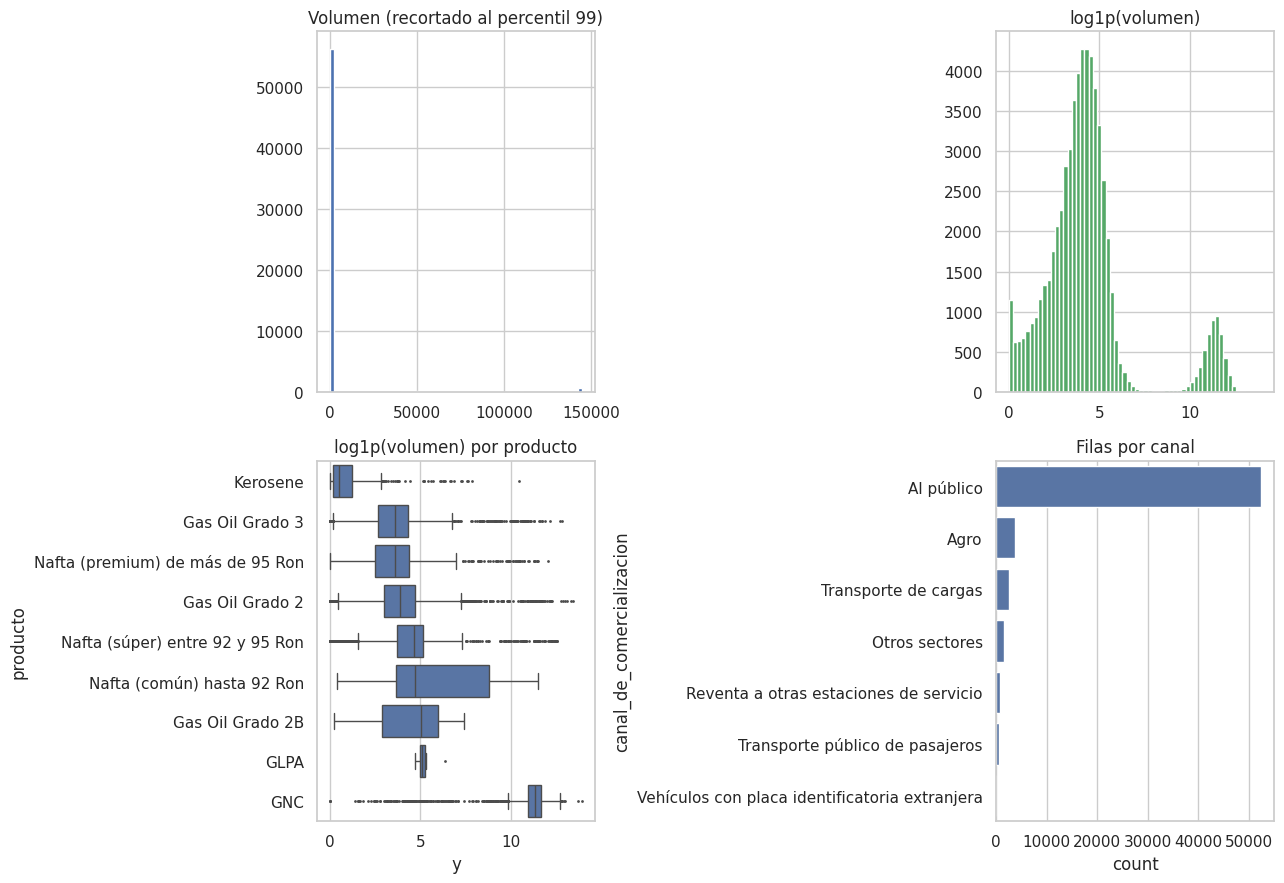

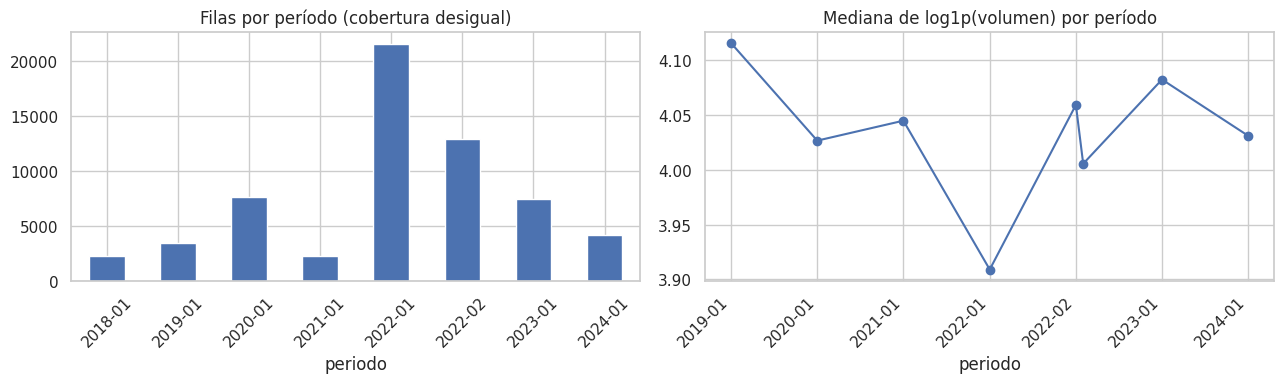

In [ ]:
# Celda 7 · Distribuciones
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
vmax = panel['volumen'].quantile(0.99)
ax[0, 0].hist(panel['volumen'].clip(upper=vmax), bins=60, color='#4c72b0')
ax[0, 0].set_title('Volumen (recortado al percentil 99)')
ax[0, 1].hist(panel['y'], bins=60, color='#55a868')
ax[0, 1].set_title('log1p(volumen)')
orden = panel.groupby('producto')['y'].median().sort_values().index
sns.boxplot(data=panel, y='producto', x='y', order=orden, ax=ax[1, 0], fliersize=1)
ax[1, 0].set_title('log1p(volumen) por producto')
sns.countplot(data=panel, y='canal_de_comercializacion', ax=ax[1, 1],
              order=panel['canal_de_comercializacion'].value_counts().index)
ax[1, 1].set_title('Filas por canal')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tmp = panel.groupby('periodo').agg(filas=('y', 'size'), y_mediana=('y', 'median'))
tmp['filas'].plot(kind='bar', ax=ax[0], color='#4c72b0'); ax[0].set_title('Filas por período (cobertura desigual)')
tmp['y_mediana'].plot(marker='o', ax=ax[1]); ax[1].set_title('Mediana de log1p(volumen) por período')
for a in ax: a.set_xticklabels([d.strftime('%Y-%m') for d in tmp.index], rotation=45)
plt.tight_layout(); plt.show()

In [ ]:
# Celda 8 · Valores atípicos (regla IQR dentro de cada producto, en escala log)
def marca_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

panel['atipico_iqr'] = panel.groupby('producto')['y'].transform(marca_iqr)
tabla = panel.groupby('producto').agg(filas=('y', 'size'), atipicos=('atipico_iqr', 'sum'))
tabla['%'] = tabla['atipicos'] / tabla['filas'] * 100
display(tabla)

print('Los 10 volúmenes más grandes (revisar si corresponden a la unidad del producto):')
display(panel.nlargest(10, 'volumen')[['periodo', 'operador', 'producto', 'canal_de_comercializacion', 'volumen', 'precio_con_impuestos']])
print('Se conservan: en escala log su influencia es acotada y no hay evidencia documental de error.')

,filas,atipicos,%
producto,,,
GLPA,10,1,10.000
GNC,5268,227,4.309
Gas Oil Grado 2,16518,423,2.561
Gas Oil Grado 2B,24,0,0.000
Gas Oil Grado 3,14016,285,2.033
Kerosene,592,37,6.250
Nafta (común) hasta 92 Ron,39,0,0.000
Nafta (premium) de más de 95 Ron,12058,55,0.456
Nafta (súper) entre 92 y 95 Ron,13185,968,7.342


Los 10 volúmenes más grandes (revisar si corresponden a la unidad del producto):


,periodo,operador,producto,canal_de_comercializacion,volumen,precio_con_impuestos
3678,2022-01-01,G.N.C. CHAVES S.A.,GNC,Al público,"1,110,980.000",50.480
22726,2023-01-01,ALVEAR I GAS S.R.L.,GNC,Al público,"891,980.000",77.990
40709,2023-01-01,ABRAHAM HNOS. S.A.,Gas Oil Grado 2,Agro,"678,900.000",199.900
60734,2022-01-01,LUBRICANTES Y COMBUSTIBLES D´ATRI SRL,Gas Oil Grado 2,Transporte de cargas,"594,500.000",92.470
60732,2022-01-01,LUBRICANTES Y COMBUSTIBLES D´ATRI SRL,Gas Oil Grado 2,Otros sectores,"465,350.000",93.180
39691,2023-01-01,COSTACOM SOCIEDAD ANONIMA,GNC,Al público,"422,693.000",96.323
5352,2022-02-01,ESTACIONES DE SERVICIOS EDARGUS S.R.L.,Gas Oil Grado 2,Al público,"417,061.000",80.036
39689,2022-01-01,COSTACOM SOCIEDAD ANONIMA,GNC,Al público,"397,297.000",47.000
60735,2022-02-01,LUBRICANTES Y COMBUSTIBLES D´ATRI SRL,Gas Oil Grado 2,Transporte de cargas,"386,766.000",99.320
39688,2020-01-01,COSTACOM SOCIEDAD ANONIMA,GNC,Al público,"369,767.000",27.000


Se conservan: en escala log su influencia es acotada y no hay evidencia documental de error.


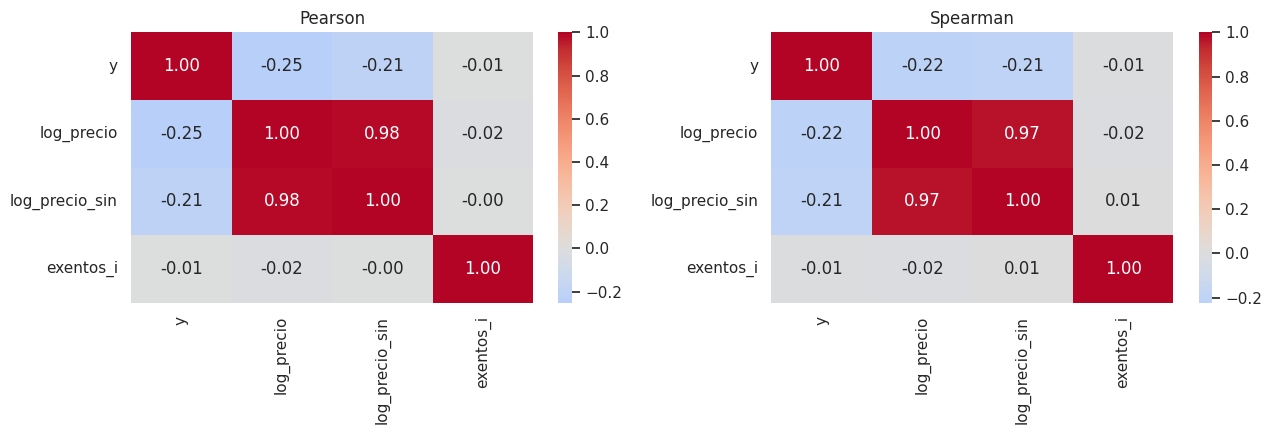

Correlación y vs log_precio DENTRO de cada producto (evita la mezcla de escalas entre productos):


producto,GLPA,GNC,Gas Oil Grado 2,Gas Oil Grado 2B,Gas Oil Grado 3,Kerosene,Nafta (común) hasta 92 Ron,Nafta (premium) de más de 95 Ron,Nafta (súper) entre 92 y 95 Ron
corr,-0.033,-0.118,0.016,-0.384,-0.020,0.055,-0.461,-0.044,-0.010


Nota: log_precio y log_precio_sin son casi colineales; se usa solo uno.


In [ ]:
# Celda 9 · Correlaciones y relaciones entre variables
panel['log_precio_sin'] = np.log(panel['precio_sin_impuestos'])
cols_corr = ['y', 'log_precio', 'log_precio_sin', 'exentos_i']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(panel[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0]); ax[0].set_title('Pearson')
sns.heatmap(panel[cols_corr].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1]); ax[1].set_title('Spearman')
plt.tight_layout(); plt.show()

print('Correlación y vs log_precio DENTRO de cada producto (evita la mezcla de escalas entre productos):')
display(panel.groupby('producto').apply(lambda d: d['y'].corr(d['log_precio'])).to_frame('corr').T)
print('Nota: log_precio y log_precio_sin son casi colineales; se usa solo uno.')

**Variables útiles y excluidas por metodología**

| Metodología | Variables usadas | Excluidas |
|---|---|---|
| SVD / K-means / DBSCAN | `y` (log volumen), `log_precio`, `exentos`, producto, canal, tipo de negocio | identificadores, texto, provincia/bandera (alta cardinalidad: ensuciarían la geometría) |
| Embeddings / ChromaDB | texto = operador + bandera + tipo de negocio + localidad + provincia + producto + canal | variables numéricas (van como metadatos) |
| Perceptrón / MLP | volumen y precio **rezagados**, brecha temporal, nº de observaciones previas, producto, canal, provincia, bandera, tipo de negocio, `exentos` | `volumen` y precio del mismo período (fuga), `mes`, `anio`, identificadores |

## 3. Preparación de variables y reducción de dimensionalidad (SVD)

**Matriz para el análisis no supervisado.** Variables numéricas estandarizadas (`y`, `log_precio`, `exentos`) + one-hot de `producto`, `canal_de_comercializacion` y `tipo_negocio`. Las dummies se **centran pero no se escalan**: escalarlas daría un peso desproporcionado a las categorías raras (p. ej. las 39 filas de "Nafta común").

> **Importante:** estos clusters usan `y` (el objetivo) y son solo **descriptivos**. No se usan como variable predictora en la sección 6 porque filtrarían el valor a predecir.

**Fundamento de SVD.** Para una matriz centrada $X \in \mathbb{R}^{n\times p}$: $X = U\Sigma V^\top$, con $U$ ($n\times p$) y $V$ ($p\times p$) de columnas ortonormales y $\Sigma=\mathrm{diag}(\sigma_1\ge\dots\ge\sigma_p\ge0)$.
- Las columnas de $V$ son las **direcciones principales** (cargas) y $Z = XV = U\Sigma$ son las **coordenadas** (puntuaciones).
- La varianza explicada por el componente $j$ es $\sigma_j^2/\sum_i\sigma_i^2$ (con $X$ centrada, SVD equivale a PCA).
- La mejor aproximación de rango $k$ (teorema de Eckart–Young) es $X_k=U_k\Sigma_kV_k^\top$ y su error relativo es $\|X-X_k\|_F^2/\|X\|_F^2 = 1-\text{varianza acumulada}$.

**Criterio para elegir $k$:** menor $k$ con ≥ 90 % de varianza acumulada, contrastado con el codo del gráfico de sedimentación.

Matriz de análisis: (61710, 31)
Componentes para >=90% de varianza: 7 (varianza acumulada 0.912)
Error relativo de reconstrucción (Frobenius²): 0.0881 = 1 - var acumulada = 0.0881


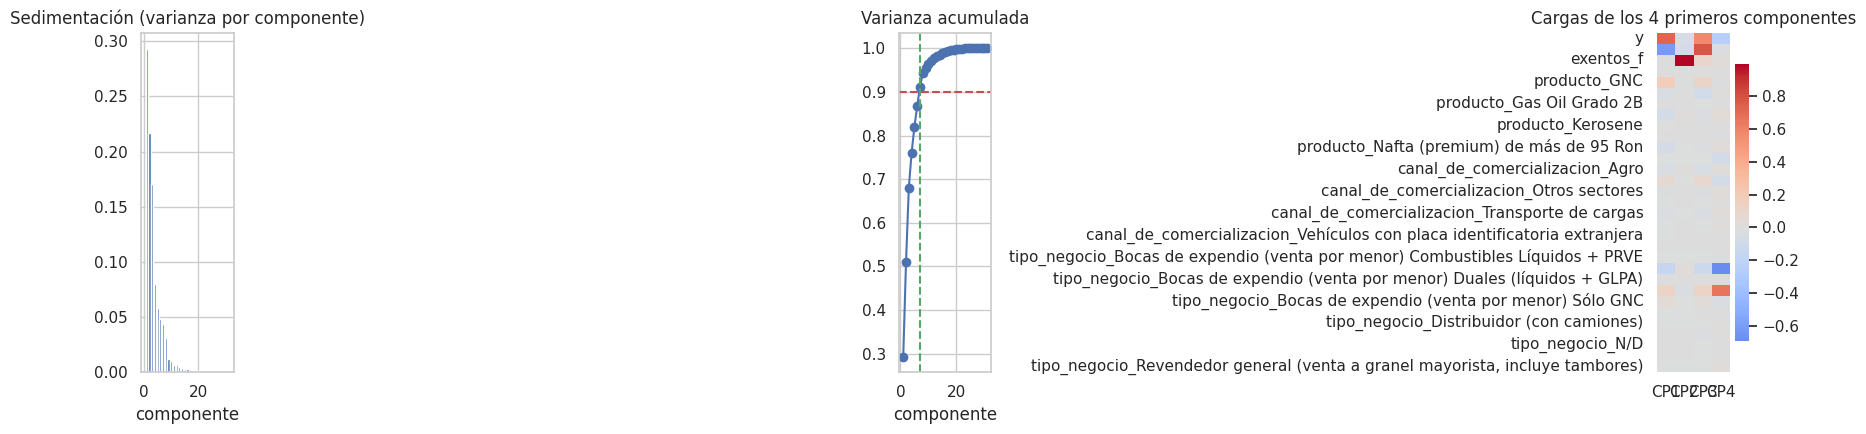

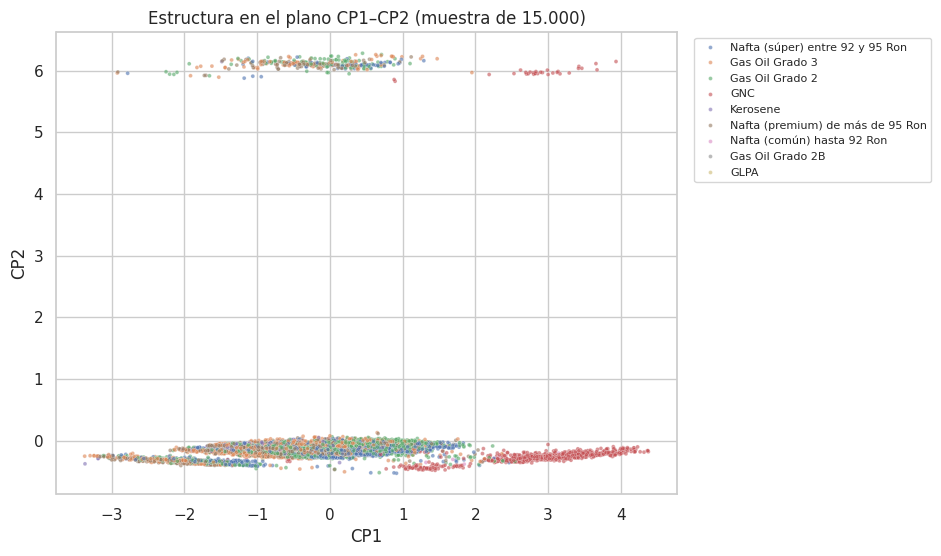

,CP1,CP2,CP3,CP4
y,0.726,0.047,0.571,0.256
log_precio,0.619,0.066,0.779,0.016
producto_GNC,0.181,0.008,0.117,0.009
tipo_negocio_Bocas de expendio (venta por menor) Combustibles líquidos únicamente,0.159,0.027,0.123,0.693
tipo_negocio_Bocas de expendio (venta por menor) Duales (líquidos + GNC),0.120,0.029,0.123,0.660
producto_Gas Oil Grado 3,0.078,0.013,0.014,0.043


In [ ]:
# Celda 10 · Matriz de análisis y SVD
panel['exentos_f'] = panel['exentos_i'].astype(float)
NUM_CL = ['y', 'log_precio', 'exentos_f']
CAT_CL = ['producto', 'canal_de_comercializacion', 'tipo_negocio']

Xn = StandardScaler().fit_transform(panel[NUM_CL])
ohe_cl = OneHotEncoder(sparse_output=False, dtype=float)
Xc = ohe_cl.fit_transform(panel[CAT_CL])
Xc = Xc - Xc.mean(axis=0)                       # centrado sin escalado
X_cl = np.hstack([Xn, Xc])
nombres_cl = NUM_CL + list(ohe_cl.get_feature_names_out(CAT_CL))
print('Matriz de análisis:', X_cl.shape)

U, S, Vt = np.linalg.svd(X_cl, full_matrices=False)
var_exp = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)
K_SVD = int(np.argmax(var_acum >= 0.90) + 1)
print(f'Componentes para >=90% de varianza: {K_SVD} (varianza acumulada {var_acum[K_SVD-1]:.3f})')

Z = X_cl @ Vt[:K_SVD].T                        # coordenadas en el subespacio reducido
err_rel = 1 - var_acum[K_SVD - 1]
X_k = (U[:, :K_SVD] * S[:K_SVD]) @ Vt[:K_SVD]
print(f'Error relativo de reconstrucción (Frobenius²): {np.linalg.norm(X_cl - X_k)**2 / np.linalg.norm(X_cl)**2:.4f} = 1 - var acumulada = {err_rel:.4f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(range(1, len(S)+1), var_exp, color='#4c72b0'); ax[0].set_title('Sedimentación (varianza por componente)'); ax[0].set_xlabel('componente')
ax[1].plot(range(1, len(S)+1), var_acum, marker='o'); ax[1].axhline(0.90, color='r', ls='--'); ax[1].axvline(K_SVD, color='g', ls='--')
ax[1].set_title('Varianza acumulada'); ax[1].set_xlabel('componente')
carga = pd.DataFrame(Vt[:4].T, index=nombres_cl, columns=[f'CP{i+1}' for i in range(4)])
sns.heatmap(carga, cmap='coolwarm', center=0, ax=ax[2]); ax[2].set_title('Cargas de los 4 primeros componentes')
plt.tight_layout(); plt.show()

idx = np.random.RandomState(SEMILLA).choice(len(Z), 15000, replace=False)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[idx, 0], y=Z[idx, 1], hue=panel['producto'].values[idx], s=8, alpha=.6)
plt.xlabel('CP1'); plt.ylabel('CP2'); plt.title('Estructura en el plano CP1–CP2 (muestra de 15.000)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.show()
display(carga.abs().sort_values('CP1', ascending=False).head(6))

Dimensiones originales de panel: (61710, 18)
Dimensiones tras filtrar los productos seleccionados: (55777, 19)
Matriz de análisis geométrica (filtrada): (55777, 25)
Componentes para >=90% de varianza: 7 (varianza acumulada 0.921)
Error relativo de reconstrucción (Frobenius²): 0.0789


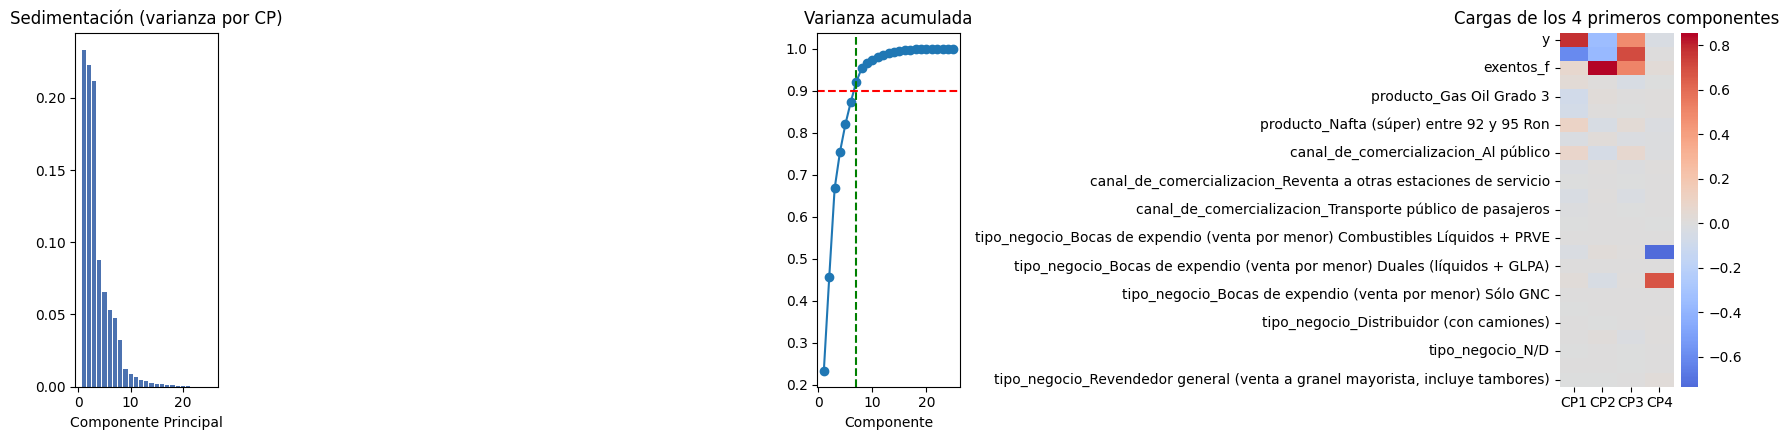

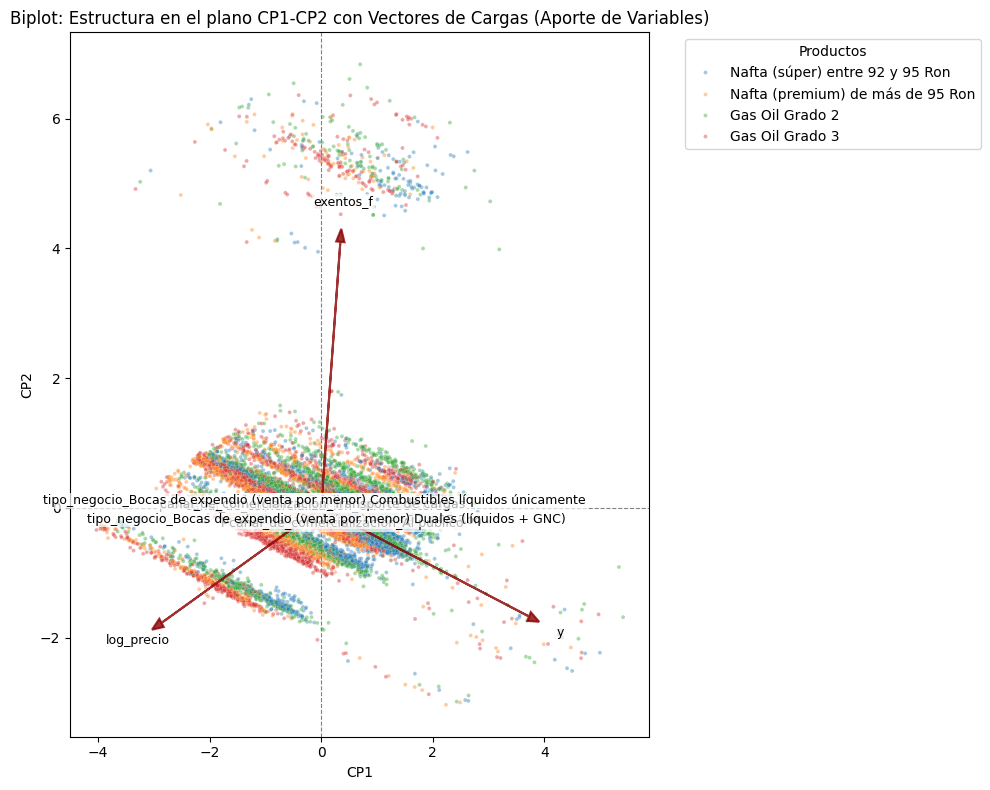

,CP1,CP2,CP3,CP4
y,0.778601,0.349931,0.483774,0.030095
log_precio,0.598000,0.370487,0.705984,0.003983
producto_Nafta (súper) entre 92 y 95 Ron,0.100038,0.036766,0.037710,0.015032
canal_de_comercializacion_Al público,0.081868,0.044585,0.064089,0.010184
producto_Gas Oil Grado 3,0.075883,0.020021,0.003074,0.008159
exentos_f,0.071855,0.856860,0.509274,0.030590


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Asegurar la carga de datos y creación de la variable 'panel'
RUTA = 'EESS_limpio.csv'
if not os.path.exists(RUTA):
    raise FileNotFoundError('Por favor, asegúrate de que EESS_limpio.csv esté subido al entorno.')

df_raw = pd.read_csv(RUTA)

df = df_raw.copy()
df['periodo'] = pd.to_datetime(df['periodo'])
df['precio_surtidor'] = df['precio_surtidor'].replace(0, np.nan)
df['exentos_i'] = df['exentos'].astype(int)

CLAVE = ['nro_inscripcion', 'producto', 'canal_de_comercializacion']

panel = (df.groupby(CLAVE + ['periodo'], as_index=False)
           .agg(volumen=('volumen', 'sum'),
                precio_con_impuestos=('precio_con_impuestos', 'mean'),
                precio_sin_impuestos=('precio_sin_impuestos', 'mean'),
                precio_surtidor=('precio_surtidor', 'mean'),
                exentos_i=('exentos_i', 'max'),
                operador=('operador', 'first'), bandera=('bandera', 'first'),
                tipo_negocio=('tipo_negocio', 'first'), localidad=('localidad', 'first'),
                provincia=('provincia', 'first'), con_baja=('fecha_de_baja', lambda s: int(s.notna().any()))))

panel['y'] = np.log1p(panel['volumen'])
panel['log_precio'] = np.log(panel['precio_con_impuestos'])
panel = panel.sort_values(CLAVE + ['periodo']).reset_index(drop=True)
panel['exentos_f'] = panel['exentos_i'].astype(float)

# 2. Definir los productos frecuentes solicitados por el usuario
productos_frecuentes = [
    'gas oil grado 2',
    'gas oil grado 3',
    'Nafta (súper) entre 92 y 95 Ron',
    'Nafta (premium) de más de 95 Ron'
]

# 3. Filtrar el panel para quedarnos con los productos seleccionados
panel_filtrado = panel.copy()
panel_filtrado['producto_clean'] = panel_filtrado['producto'].str.lower().str.strip()
productos_frecuentes_clean = [p.lower().strip() for p in productos_frecuentes]

panel_filtrado = panel_filtrado[panel_filtrado['producto_clean'].isin(productos_frecuentes_clean)].copy()
print(f"Dimensiones originales de panel: {panel.shape}")
print(f"Dimensiones tras filtrar los productos seleccionados: {panel_filtrado.shape}")

# 4. Reconstrucción de la matriz geométrica idéntica a la Celda 10
NUM_CL = ['y', 'log_precio', 'exentos_f']
CAT_CL = ['producto', 'canal_de_comercializacion', 'tipo_negocio']

Xn = StandardScaler().fit_transform(panel_filtrado[NUM_CL])
ohe_cl = OneHotEncoder(sparse_output=False, dtype=float, handle_unknown='ignore')
Xc = ohe_cl.fit_transform(panel_filtrado[CAT_CL])
Xc = Xc - Xc.mean(axis=0)                       # Centrado sin escalado para variables dummy
X_cl = np.hstack([Xn, Xc])
nombres_cl = NUM_CL + list(ohe_cl.get_feature_names_out(CAT_CL))
print('Matriz de análisis geométrica (filtrada):', X_cl.shape)

# 5. Descomposición en Valores Singulares (SVD)
U, S, Vt = np.linalg.svd(X_cl, full_matrices=False)
var_exp = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)
SEMILLA = 42
K_SVD = int(np.argmax(var_acum >= 0.90) + 1)
print(f'Componentes para >=90% de varianza: {K_SVD} (varianza acumulada {var_acum[K_SVD-1]:.3f})')

Z = X_cl @ Vt[:K_SVD].T
err_rel = 1 - var_acum[K_SVD - 1]
X_k = (U[:, :K_SVD] * S[:K_SVD]) @ Vt[:K_SVD]
print(f'Error relativo de reconstrucción (Frobenius²): {np.linalg.norm(X_cl - X_k)**2 / np.linalg.norm(X_cl)**2:.4f}')

# 6. Visualización de resultados tradicionales
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(range(1, len(S)+1), var_exp, color='#4c72b0')
ax[0].set_title('Sedimentación (varianza por CP)')
ax[0].set_xlabel('Componente Principal')

ax[1].plot(range(1, len(S)+1), var_acum, marker='o')
ax[1].axhline(0.90, color='r', ls='--')
ax[1].axvline(K_SVD, color='g', ls='--')
ax[1].set_title('Varianza acumulada')
ax[1].set_xlabel('Componente')

carga = pd.DataFrame(Vt[:4].T, index=nombres_cl, columns=[f'CP{i+1}' for i in range(4)])
sns.heatmap(carga, cmap='coolwarm', center=0, ax=ax[2])
ax[2].set_title('Cargas de los 4 primeros componentes')
plt.tight_layout()
plt.show()

# 7. Plano Proyectado con Vectores de Aporte de Variables (BIPLOT)
idx = np.random.RandomState(SEMILLA).choice(len(Z), min(15000, len(Z)), replace=False)
plt.figure(figsize=(10, 8))

# Graficar los puntos proyectados
sns.scatterplot(x=Z[idx, 0], y=Z[idx, 1], hue=panel_filtrado['producto'].values[idx], s=8, alpha=.4)

# Extraer las cargas de las variables para CP1 y CP2
loadings_cp1 = Vt[0, :]
loadings_cp2 = Vt[1, :]

# Multiplicador para escalar la longitud de las flechas dentro del rango del plot
escala_vectores = np.max(np.abs(Z[idx, :2])) * 0.7

# Para no saturar el gráfico, graficamos los vectores con mayor magnitud en CP1 o CP2
magnitudes = np.hypot(loadings_cp1, loadings_cp2)
limite_magnitud = np.percentile(magnitudes, 50) # Mostrar la mitad de variables más relevantes

for i, feature in enumerate(nombres_cl):
    if magnitudes[i] >= limite_magnitud:
        dx = loadings_cp1[i] * escala_vectores
        dy = loadings_cp2[i] * escala_vectores
        # Dibujar la flecha indicadora del vector de aporte
        plt.arrow(0, 0, dx, dy, color='darkred', alpha=0.8, head_width=0.15, head_length=0.2, lw=1.5)
        # Añadir texto descriptivo para la variable correspondiente
        plt.text(dx * 1.15, dy * 1.15, feature, color='black', ha='center', va='center', fontsize=9,
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('CP1')
plt.ylabel('CP2')
plt.title('Biplot: Estructura en el plano CP1-CP2 con Vectores de Cargas (Aporte de Variables)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Productos')
plt.tight_layout()
plt.show()

display(carga.abs().sort_values('CP1', ascending=False).head(6))


Dimensiones resultantes para SVD: 42316 registros.
Variables numéricas incluidas: ['y', 'log_precio', 'exentos_f', 'anio']
Variables categóricas incluidas (dummies): ['bandera', 'tipo_negocio', 'canal_de_comercializacion', 'localidad_proc']
Matriz final para SVD: (42316, 145)
Componentes necesarios para >=90% de varianza explicada: 16 (varianza acumulada: 90.383%)


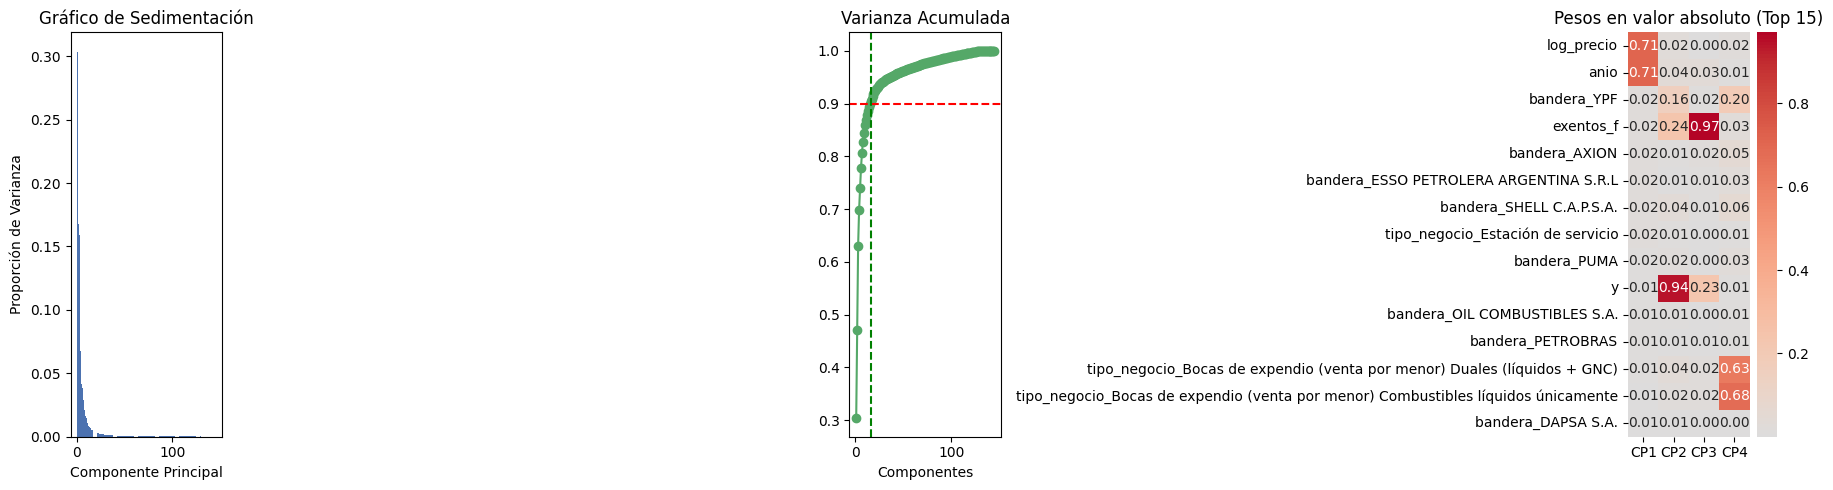

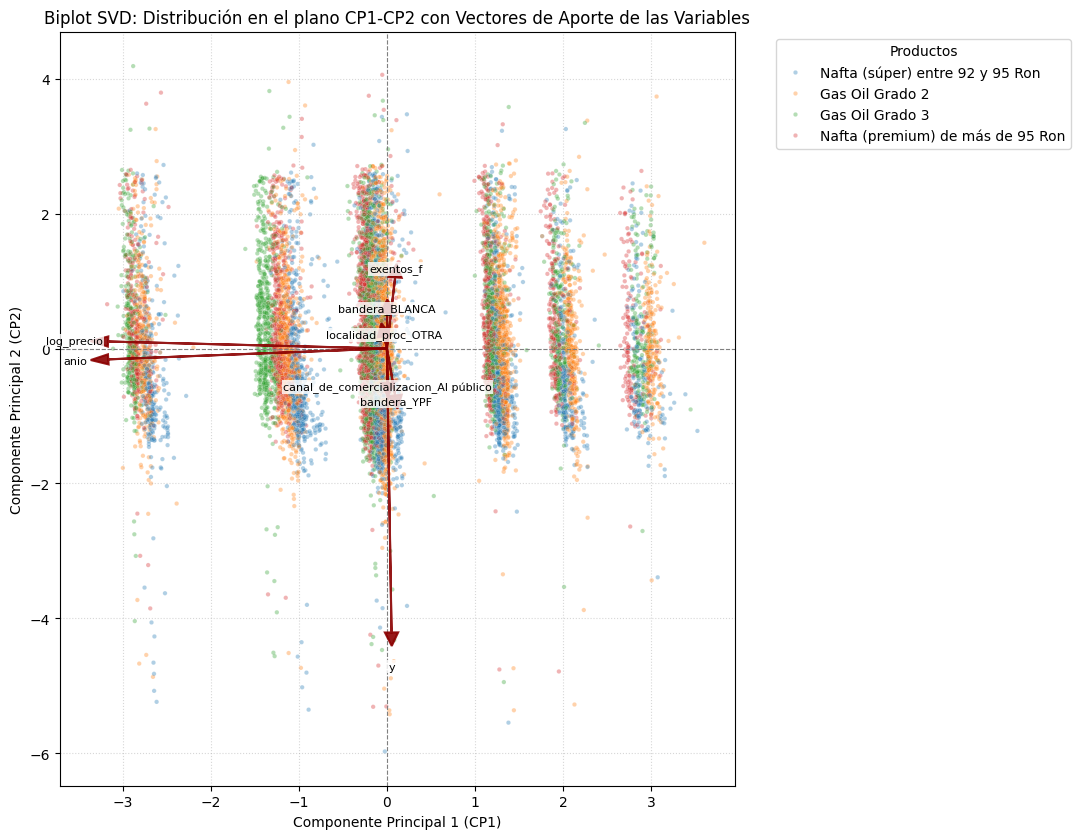

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Cargar el dataset de origen
RUTA = 'EESS_limpio.csv'
if not os.path.exists(RUTA):
    raise FileNotFoundError('Asegúrate de que EESS_limpio.csv esté disponible en el entorno de trabajo.')

df_raw = pd.read_csv(RUTA)
# Se realiza una copia profunda para preservar el objeto original de manera segura
df_proc = df_raw.copy()

# 2. Filtrar por los 4 productos más frecuentes
productos_frecuentes = [
    'gas oil grado 2',
    'gas oil grado 3',
    'Nafta (súper) entre 92 y 95 Ron',
    'Nafta (premium) de más de 95 Ron'
]
df_proc['producto_clean'] = df_proc['producto'].str.lower().str.strip()
productos_clean = [p.lower().strip() for p in productos_frecuentes]
df_proc = df_proc[df_proc['producto_clean'].isin(productos_clean)].copy()

# 3. Tratamiento de anomalías y exclusión de variables predictoras
# - Se descarta el año 2021 debido al cambio drástico de tendencia por la pandemia
df_proc = df_proc[df_proc['anio'] != 2021].copy()

# - Se eliminan predictoras explícitas: 'mes', 'provincia'
# - Nos quedamos con 'localidad' que es más específica que 'provincia'
# - Tratamiento de NaN en exentos
df_proc['exentos_i'] = df_proc['exentos'].fillna(0).astype(int).astype(float)

# 4. Agrupamiento a nivel de clave para consolidar volumen en escala logarítmica
CLAVE = ['nro_inscripcion', 'producto', 'canal_de_comercializacion']
panel_svd = (df_proc.groupby(CLAVE + ['anio'], as_index=False)
             .agg(volumen=('volumen', 'sum'),
                  precio_con_impuestos=('precio_con_impuestos', 'mean'),
                  exentos_f=('exentos_i', 'max'),
                  bandera=('bandera', 'first'),
                  tipo_negocio=('tipo_negocio', 'first'),
                  localidad=('localidad', 'first')))

# Transformación logarítmica del volumen y precio
panel_svd['y'] = np.log1p(panel_svd['volumen'])
panel_svd['log_precio'] = np.log(panel_svd['precio_con_impuestos'].replace(0, np.nan))
panel_svd['log_precio'] = panel_svd['log_precio'].fillna(panel_svd['log_precio'].median())

# ==========================================
# PRUEBAS DE VARIABLES (Punto 3 del requerimiento)
# ==========================================
NUM_VARS = ['y', 'log_precio', 'exentos_f', 'anio']
CAT_VARS = ['bandera', 'tipo_negocio', 'canal_de_comercializacion', 'localidad']

# Ajuste robusto de alta cardinalidad en Localidad (filtramos a las más frecuentes para evitar sobre-dispersión)
localidades_frec = panel_svd['localidad'].value_counts().head(100).index
panel_svd['localidad_proc'] = panel_svd['localidad'].where(panel_svd['localidad'].isin(localidades_frec), 'OTRA')
CAT_VARS[CAT_VARS.index('localidad')] = 'localidad_proc'

print(f"Dimensiones resultantes para SVD: {panel_svd.shape[0]} registros.")
print(f"Variables numéricas incluidas: {NUM_VARS}")
print(f"Variables categóricas incluidas (dummies): {CAT_VARS}")

# 5. Preprocesamiento Geométrico
Xn = StandardScaler().fit_transform(panel_svd[NUM_VARS])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
Xc = ohe.fit_transform(panel_svd[CAT_VARS])
Xc = Xc - Xc.mean(axis=0)  # Centrado sin escalado

X_geom = np.hstack([Xn, Xc])
feature_names = NUM_VARS + list(ohe.get_feature_names_out(CAT_VARS))
print(f"Matriz final para SVD: {X_geom.shape}")

# 6. Descomposición en Valores Singulares (SVD)
U, S, Vt = np.linalg.svd(X_geom, full_matrices=False)
var_exp = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)

K_SVD = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes necesarios para >=90% de varianza explicada: {K_SVD} (varianza acumulada: {var_acum[K_SVD-1]:.3%})")

# Coordenadas y proyección
Z = X_geom @ Vt[:K_SVD].T

# 7. Gráficos de diagnóstico y estructura
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].bar(range(1, len(S)+1), var_exp, color='#4c72b0')
ax[0].set_title('Gráfico de Sedimentación')
ax[0].set_xlabel('Componente Principal')
ax[0].set_ylabel('Proporción de Varianza')

ax[1].plot(range(1, len(S)+1), var_acum, marker='o', color='#55a868')
ax[1].axhline(0.90, color='r', ls='--')
ax[1].axvline(K_SVD, color='g', ls='--')
ax[1].set_title('Varianza Acumulada')
ax[1].set_xlabel('Componentes')

cargas = pd.DataFrame(Vt[:4].T, index=feature_names, columns=[f'CP{i+1}' for i in range(4)])
sns.heatmap(cargas.abs().sort_values('CP1', ascending=False).head(15), cmap='coolwarm', center=0, ax=ax[2], annot=True, fmt='.2f')
ax[2].set_title('Pesos en valor absoluto (Top 15)')
plt.tight_layout()
plt.show()

# 8. Biplot: Proyección en CP1 - CP2 con vectores de aporte ploteados
plt.figure(figsize=(11, 8.5))
SEMILLA = 42
idx_plot = np.random.RandomState(SEMILLA).choice(len(Z), min(15000, len(Z)), replace=False)

# Dibujar nube de puntos
sns.scatterplot(x=Z[idx_plot, 0], y=Z[idx_plot, 1], hue=panel_svd['producto'].values[idx_plot], s=10, alpha=0.35)

# Extraer coeficientes (loadings) de las variables para CP1 y CP2
loadings_cp1 = Vt[0, :]
loadings_cp2 = Vt[1, :]

# Factor multiplicador automático para que las flechas tengan dimensiones proporcionales a los datos
escala_flechas = np.max(np.abs(Z[idx_plot, :2])) * 0.75

# Dado que hay 145 variables por one-hot, seleccionamos las más influyentes
# Evaluamos la norma euclídea en los primeros 2 componentes para filtrar
magnitud_loadings = np.hypot(loadings_cp1, loadings_cp2)
# Umbral alto para evitar colapso visual (solo mostrar las variables en el percentil 95 o numéricas base)
umbral_visibilidad = np.percentile(magnitud_loadings, 95)

for i, nombre_var in enumerate(feature_names):
    # Graficar variables numéricas clave o aquellas categóricas de alto peso
    if nombre_var in NUM_VARS or magnitud_loadings[i] >= umbral_visibilidad:
        dx = loadings_cp1[i] * escala_flechas
        dy = loadings_cp2[i] * escala_flechas

        # Dibujar flecha del vector de aporte
        plt.arrow(0, 0, dx, dy, color='darkred', alpha=0.9, head_width=0.15, head_length=0.2, lw=1.5, zorder=5)

        # Colocar nombre de la variable en el extremo del vector
        plt.text(dx * 1.12, dy * 1.12, nombre_var, color='black', ha='center', va='center', fontsize=8,
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1), zorder=6)

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Componente Principal 1 (CP1)')
plt.ylabel('Componente Principal 2 (CP2)')
plt.title('Biplot SVD: Distribución en el plano CP1-CP2 con Vectores de Aporte de las Variables')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Productos')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import unicodedata
import re
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# ==========================================
# 1. Preparación del Modelo (df_limpio_mp_vf)
# ==========================================
df_limpio = df_raw.copy()  # Aseguramos existencia del df base de origen

df_preparacion_modelo = df_limpio.copy()
df_preparacion_modelo['producto'] = df_preparacion_modelo['producto'].astype(str).str.strip()

productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_preparacion_modelo = df_preparacion_modelo[
    df_preparacion_modelo['producto'].isin(productos_frecuentes)
].copy()

df_preparacion_modelo = df_preparacion_modelo[
    (df_preparacion_modelo['sin_movimientos'] == False) &
    (df_preparacion_modelo['volumen'] > 0) &
    (df_preparacion_modelo['volumen'].notna())
].copy()

target = "volumen"
columnas_excluir = [
    'id', 'id_1', 'cuit', 'direccion', 'fecha_de_baja', 'sin_movimientos',
    'precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'no_novimientos', 'exentos', 'nro_inscripcion', 'periodo'
]

columnas_disponibles = df_preparacion_modelo.columns.tolist()
predictores = [col for col in columnas_disponibles if col != target and col not in columnas_excluir]

df_limpio_mp_vf = df_preparacion_modelo[predictores + [target]].copy()

print("=== DATASET PREPARADO PARA MODELADO ===")
print(f"Dimensiones de df_limpio_mp_vf: {df_limpio_mp_vf.shape[0]} filas, {df_limpio_mp_vf.shape[1]} columnas.")
print(f"Variable objetivo (Target): {target}")
print(f"Predictores incluidos en el dataset: {predictores}")
display(df_limpio_mp_vf.head())

# ==========================================
# 2. Preparación de Negocio
# ==========================================
df_preparado_negocio = df_limpio.copy()
print(f"\nDimensiones iniciales del dataset de negocio: {df_preparado_negocio.shape[0]} filas")

def normalizar_texto_negocio(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().upper()
    texto = "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )
    texto = texto.replace(".", "").replace("(", "").replace(")", "")
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()

df_preparado_negocio['tipo_negocio_norm'] = df_preparado_negocio['tipo_negocio'].apply(normalizar_texto_negocio)

patron_bocas = "BOCAS DE EXPENDIO"
patron_estacion = "ESTACION DE SERVICIO"

filtro_minorista = (
    df_preparado_negocio['tipo_negocio_norm'].str.contains(patron_bocas, na=False, regex=False) |
    df_preparado_negocio['tipo_negocio_norm'].str.contains(patron_estacion, na=False, regex=False)
)

df_preparado_negocio = df_preparado_negocio[filtro_minorista].copy()
df_preparado_negocio = df_preparado_negocio.drop(columns=['tipo_negocio_norm'])

print(f"Dimensiones después de filtrar por venta minorista: {df_preparado_negocio.shape[0]} filas")

df_preparado_negocio['operador'] = df_preparado_negocio['operador'].apply(normalizar_texto_negocio)
df_preparado_negocio['localidad'] = df_preparado_negocio['localidad'].apply(normalizar_texto_negocio)

# ==========================================
# 3. Configuración, Agrupamientos y Split
# ==========================================
ANIO_PANDEMIA = 2021
OPERADOR_ACA = "AUTOMOVIL CLUB ARGENTINO"

N_LOCALIDAD = 100
N_BANDERA = 100
N_OPERADOR = 200

FRAC_TEST = 0.2
CATEGORICAS = {"producto", "localidad_ag", "bandera_ag", "provincia", "operador_ag"}

def crear_variables_base(df):
    df = df.copy()
    df["pandemia"] = (df["anio"] == ANIO_PANDEMIA).astype(int)
    df["periodo"] = df["anio"] * 100 + df["mes"]
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)
    return df

def split_cronologico(df, frac_test=FRAC_TEST):
    periodos = np.sort(df["periodo"].unique())
    corte = periodos[int(len(periodos) * (1 - frac_test)) - 1]
    train = df[df["periodo"] <= corte].copy()
    test = df[df["periodo"] > corte].copy()
    print(f"Train hasta {corte}: {len(train)} filas | Test: {len(test)} filas")
    return train, test

def ajustar_agrupaciones(train):
    def frecuentes(col, n):
        vc = train[col].value_counts()
        return set(vc[vc >= n].index)
    return {
        "localidad": frecuentes("localidad", N_LOCALIDAD),
        "bandera": frecuentes("bandera", N_BANDERA),
        "operador": frecuentes("operador", N_OPERADOR),
    }

def aplicar_agrupaciones(df, ref):
    df = df.copy()
    df["localidad_ag"] = df["localidad"].where(
        df["localidad"].isin(ref["localidad"]), "OTRAS - " + df["provincia"]
    )
    df["bandera_ag"] = df["bandera"].where(df["bandera"].isin(ref["bandera"]), "OTRAS")
    df["operador_ag"] = df["operador"].where(df["operador"].isin(ref["operador"]), "OTROS")
    df["operador_aca"] = (df["operador"] == OPERADOR_ACA).astype(int)
    return df

def construir_X(train, test, columnas, lineal):
    cols = []
    for c in columnas:
        cols += ["mes_sin", "mes_cos"] if (c == "mes" and lineal) else [c]
    cat = [c for c in cols if c in CATEGORICAS]
    num = [c for c in cols if c not in CATEGORICAS]
    codificador = OneHotEncoder(
        handle_unknown="ignore",
        drop="first" if lineal else None,
        sparse_output=False,
    )
    ct = ColumnTransformer(
        [("cat", codificador, cat), ("num", "passthrough", num)],
        verbose_feature_names_out=False,
    )
    ct.set_output(transform="pandas")
    X_train = ct.fit_transform(train[cols])
    X_test = ct.transform(test[cols])
    return X_train, X_test, ct

def transformar_objetivo(volumen):
    return np.log1p(volumen)

def revertir_objetivo(pred_log):
    return np.clip(np.expm1(pred_log), 0, None)

=== DATASET PREPARADO PARA MODELADO ===
Dimensiones de df_limpio_mp_vf: 55836 filas, 10 columnas.
Variable objetivo (Target): volumen
Predictores incluidos en el dataset: ['anio', 'mes', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']


,anio,mes,operador,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion,volumen
0,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (lí...,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,23.040
1,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (lí...,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,3.880
2,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (lí...,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.240
3,2018,1,10 DE SETIEMBRE S.A.,BLANCA,Bocas de expendio (venta por menor) Duales (lí...,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,3.560
5,2018,1,17 DE SETIEMBRE S.R.L.,YPF,Estación de servicio,MARCOS PAZ,BUENOS AIRES,Gas Oil Grado 2,Al público,2.700



Dimensiones iniciales del dataset de negocio: 61771 filas
Dimensiones después de filtrar por venta minorista: 58711 filas


Dimensiones para PCA/SVD: 55836 registros.
Matriz final para descomposición: (55836, 71)
Componentes para >=90% de varianza explicada: 18 (acumulada: 90.356%)


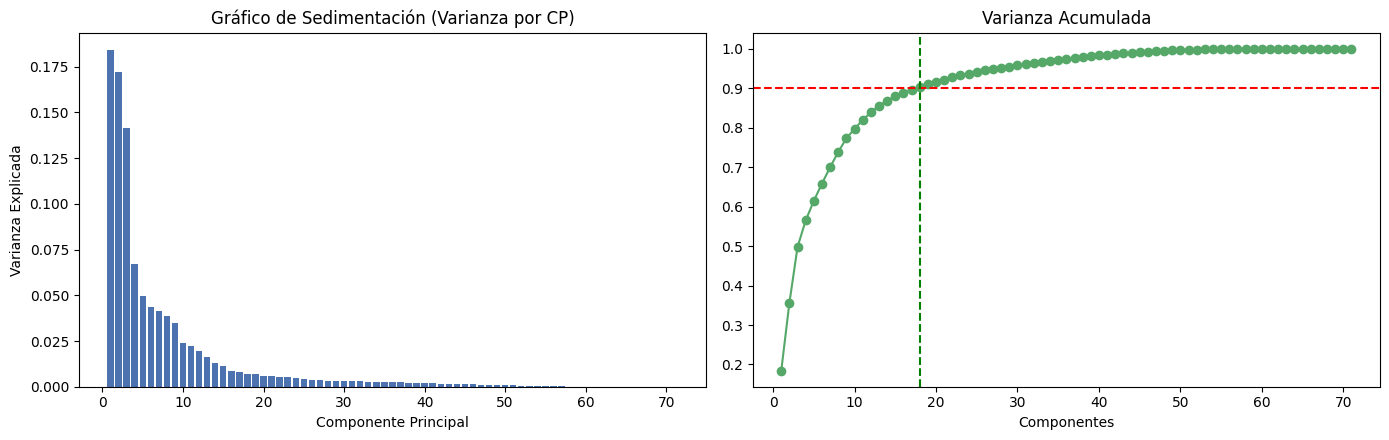

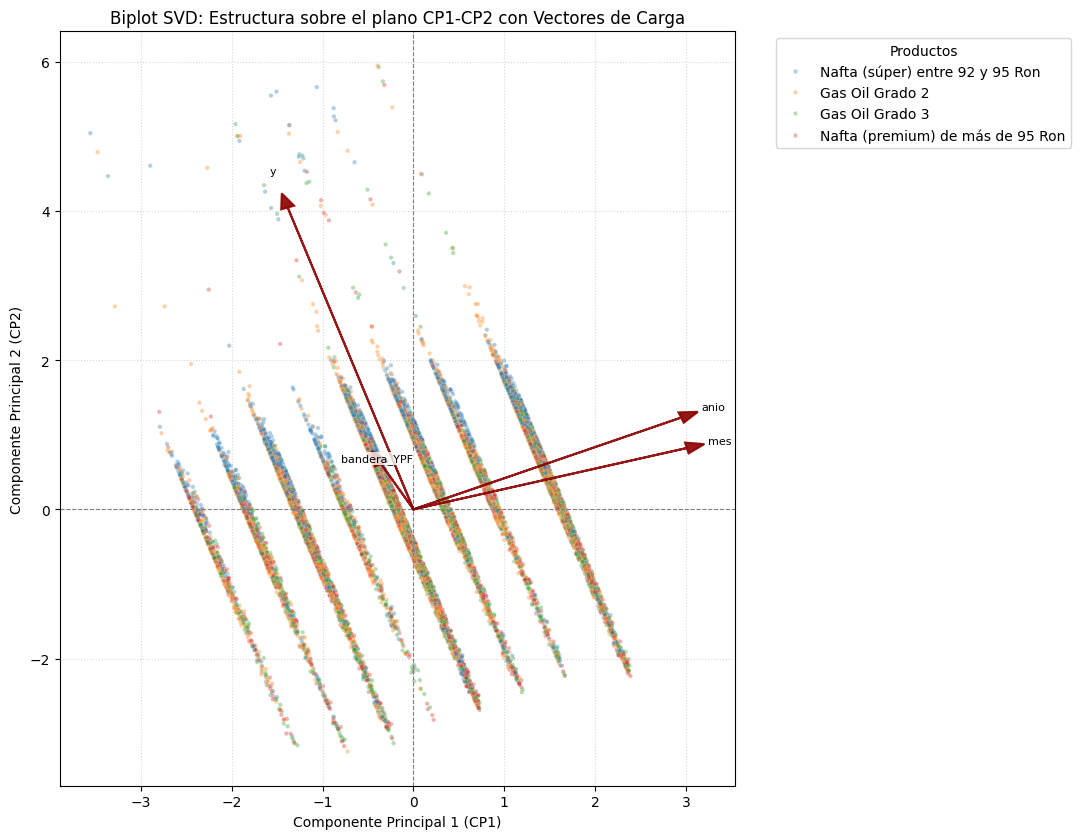

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Asegurar la existencia de df_raw y preparar el dataset de modelado localmente
if 'df_raw' not in globals():
    RUTA = 'EESS_limpio.csv'
    if os.path.exists(RUTA):
        df_raw = pd.read_csv(RUTA)
    else:
        raise FileNotFoundError('Asegúrate de que EESS_limpio.csv esté disponible en el entorno de trabajo.')

# Filtros idénticos para el dataset consolidado de modelado
df_svd = df_raw.copy()
df_svd['producto'] = df_svd['producto'].astype(str).str.strip()

productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_svd = df_svd[
    df_svd['producto'].isin(productos_frecuentes) &
    (df_svd['sin_movimientos'] == False) &
    (df_svd['volumen'] > 0) &
    (df_svd['volumen'].notna())
].copy()

# Agregamos la variable objetivo logarítmica
df_svd['y'] = np.log1p(df_svd['volumen'])

# 2. Definir las variables para el preprocesamiento geométrico
NUM_VARS = ['y', 'anio', 'mes']
CAT_VARS = ['producto', 'canal_de_comercializacion', 'tipo_negocio', 'provincia', 'bandera']

print(f"Dimensiones para PCA/SVD: {df_svd.shape[0]} registros.")

# 3. Preprocesamiento geométrico (Estandarización y One-Hot Encoding con centrado)
Xn = StandardScaler().fit_transform(df_svd[NUM_VARS])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
Xc = ohe.fit_transform(df_svd[CAT_VARS])
Xc = Xc - Xc.mean(axis=0)  # Centrado sin escalado

X_geom = np.hstack([Xn, Xc])
feature_names = NUM_VARS + list(ohe.get_feature_names_out(CAT_VARS))
print(f"Matriz final para descomposición: {X_geom.shape}")

# 4. Descomposición en Valores Singulares (SVD / PCA)
U, S, Vt = np.linalg.svd(X_geom, full_matrices=False)
var_exp = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)

K_SVD = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes para >=90% de varianza explicada: {K_SVD} (acumulada: {var_acum[K_SVD-1]:.3%})")

# Proyectar sobre los componentes principales
Z = X_geom @ Vt[:K_SVD].T

# 5. Graficar la varianza explicada
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(S)+1), var_exp, color='#4c72b0')
ax[0].set_title('Gráfico de Sedimentación (Varianza por CP)')
ax[0].set_xlabel('Componente Principal')
ax[0].set_ylabel('Varianza Explicada')

ax[1].plot(range(1, len(S)+1), var_acum, marker='o', color='#55a868')
ax[1].axhline(0.90, color='r', ls='--')
ax[1].axvline(K_SVD, color='g', ls='--')
ax[1].set_title('Varianza Acumulada')
ax[1].set_xlabel('Componentes')
plt.tight_layout()
plt.show()

# 6. Biplot: Proyección en CP1 - CP2 con vectores de aporte ploteados
plt.figure(figsize=(11, 8.5))
SEMILLA = 42
idx_plot = np.random.RandomState(SEMILLA).choice(len(Z), min(15000, len(Z)), replace=False)

# Dibujar nube de puntos de las observaciones
sns.scatterplot(x=Z[idx_plot, 0], y=Z[idx_plot, 1], hue=df_svd['producto'].values[idx_plot], s=10, alpha=0.35)

# Extraer las cargas de las variables para CP1 y CP2
loadings_cp1 = Vt[0, :]
loadings_cp2 = Vt[1, :]

# Escalar los vectores proporcionalmente para que se visualicen correctamente sobre la dispersión de los puntos
escala_flechas = np.max(np.abs(Z[idx_plot, :2])) * 0.75

# Filtrar para graficar únicamente las variables de mayor impacto (percentil 95 o numéricas)
magnitud_loadings = np.hypot(loadings_cp1, loadings_cp2)
umbral_visibilidad = np.percentile(magnitud_loadings, 95)

for i, nombre_var in enumerate(feature_names):
    if nombre_var in NUM_VARS or magnitud_loadings[i] >= umbral_visibilidad:
        dx = loadings_cp1[i] * escala_flechas
        dy = loadings_cp2[i] * escala_flechas

        # Dibujar vector de aporte
        plt.arrow(0, 0, dx, dy, color='darkred', alpha=0.9, head_width=0.15, head_length=0.2, lw=1.5, zorder=5)

        # Etiqueta de la variable
        plt.text(dx * 1.12, dy * 1.12, nombre_var, color='black', ha='center', va='center', fontsize=8,
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1), zorder=6)

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Componente Principal 1 (CP1)')
plt.ylabel('Componente Principal 2 (CP2)')
plt.title('Biplot SVD: Estructura sobre el plano CP1-CP2 con Vectores de Carga')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Productos')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Celda 10 · Matriz de análisis y SVD (Adaptado al nuevo dataset consolidado)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Creamos el target transformado (log) en nuestro dataset de modelado final consolidado
df_modelado = df_limpio_mp_vf.copy()
df_modelado['y'] = np.log1p(df_modelado['volumen'])

# Definimos las variables a incluir en el análisis descriptivo SVD
NUM_CL = ['y', 'anio', 'mes']
CAT_CL = ['producto', 'canal_de_comercializacion', 'tipo_negocio', 'provincia', 'bandera']

# Preprocesamiento geométrico sin fuga de información de magnitudes categóricas
Xn = StandardScaler().fit_transform(df_modelado[NUM_CL])
ohe_cl = OneHotEncoder(sparse_output=False, dtype=float, handle_unknown='ignore')
Xc = ohe_cl.fit_transform(df_modelado[CAT_CL])
Xc = Xc - Xc.mean(axis=0)                       # Centrado sin escalado para dummies
X_cl = np.hstack([Xn, Xc])
nombres_cl = NUM_CL + list(ohe_cl.get_feature_names_out(CAT_CL))
print('Matriz de análisis geométrica:', X_cl.shape)

# Descomposición en Valores Singulares (SVD)
U, S, Vt = np.linalg.svd(X_cl, full_matrices=False)
var_exp = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)
K_SVD = int(np.argmax(var_acum >= 0.90) + 1)
print(f'Componentes requeridos para >=90% de varianza: {K_SVD} (varianza acumulada {var_acum[K_SVD-1]:.3f})')

Z = X_cl @ Vt[:K_SVD].T                        # Coordenadas en el subespacio SVD reducido
err_rel = 1 - var_acum[K_SVD - 1]
X_k = (U[:, :K_SVD] * S[:K_SVD]) @ Vt[:K_SVD]
print(f'Error relativo de reconstrucción (Frobenius²): {np.linalg.norm(X_cl - X_k)**2 / np.linalg.norm(X_cl)**2:.4f} = 1 - var acumulada = {err_rel:.4f}')

# Visualización de los autovalores y cargas principales
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(range(1, len(S)+1), var_exp, color='#4c72b0')
ax[0].set_title('Sedimentación (varianza por CP)')
ax[0].set_xlabel('Componente Principal')

ax[1].plot(range(1, len(S)+1), var_acum, marker='o')
ax[1].axhline(0.90, color='r', ls='--')
ax[1].axvline(K_SVD, color='g', ls='--')
ax[1].set_title('Varianza acumulada')
ax[1].set_xlabel('Componente')

carga = pd.DataFrame(Vt[:4].T, index=nombres_cl, columns=[f'CP{i+1}' for i in range(4)])
sns.heatmap(carga, cmap='coolwarm', center=0, ax=ax[2])
ax[2].set_title('Cargas de los 4 primeros componentes')
plt.tight_layout()
plt.show()

# Estructura del espacio reducido en una muestra representativa de 15.000 registros
idx = np.random.RandomState(SEMILLA).choice(len(Z), 15000, replace=False)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[idx, 0], y=Z[idx, 1], hue=df_modelado['producto'].values[idx], s=8, alpha=.6)
plt.xlabel('CP1')
plt.ylabel('CP2')
plt.title('Estructura en el plano CP1–CP2 (Muestra de 15.000)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()

display(carga.abs().sort_values('CP1', ascending=False).head(6))

NameError: name 'df_limpio_mp_vf' is not defined

**Lectura de resultados (ejecución de referencia, semilla 42).** Se pasa de **31 dimensiones a 7 componentes reteniendo ≈ 91 % de la varianza** (error relativo de reconstrucción ≈ 0,09). CP1 (≈ 29 %) está dominado por `y` y `log_precio` junto con el indicador de GNC: separa los productos de volumen enorme (GNC) y los registros de precio alto. CP3 vuelve a combinar `y` y `log_precio`, y CP4 está dominado por el tipo de negocio (solo líquidos vs. duales líquidos + GNC). Las dummies aportan dimensiones casi independientes, por eso hacen falta varios componentes; se acepta perder ≤ 10 % de varianza a cambio de un espacio más compacto, donde la distancia euclídea es más estable para K-means y DBSCAN.

## 4. Aprendizaje no supervisado: clustering

### 4.1 K-means
**Por qué:** es rápido, escala bien y entrega centroides interpretables como "perfiles" de venta. **Supuestos:** grupos aproximadamente esféricos y de tamaño similar; todas las observaciones deben pertenecer a algún grupo; sensible a atípicos.

**Elección de $k$:** método del codo (inercia $=\sum\|x-\mu_{c(x)}\|^2$) + *silhouette* ($s=\frac{b-a}{\max(a,b)}\in[-1,1]$). Se reportan también Davies-Bouldin (menor es mejor) y Calinski-Harabasz (mayor es mejor). El silhouette se calcula sobre una muestra de 10.000 puntos por costo $O(n^2)$.

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"197,828.876",0.656,0.513,"19,263.811"
3,"142,533.549",0.477,0.612,"25,337.842"
4,"112,077.253",0.349,0.950,"27,071.234"
5,"93,614.583",0.286,1.147,"27,349.728"
6,"83,134.625",0.276,1.201,"26,193.148"
7,"74,626.741",0.313,1.115,"25,488.128"
8,"66,717.145",0.348,0.978,"25,481.614"
9,"60,670.614",0.351,0.975,"25,286.769"
10,"56,765.050",0.371,0.994,"24,495.001"


k sugerido por codo: 5 | k con mayor silhouette: 2


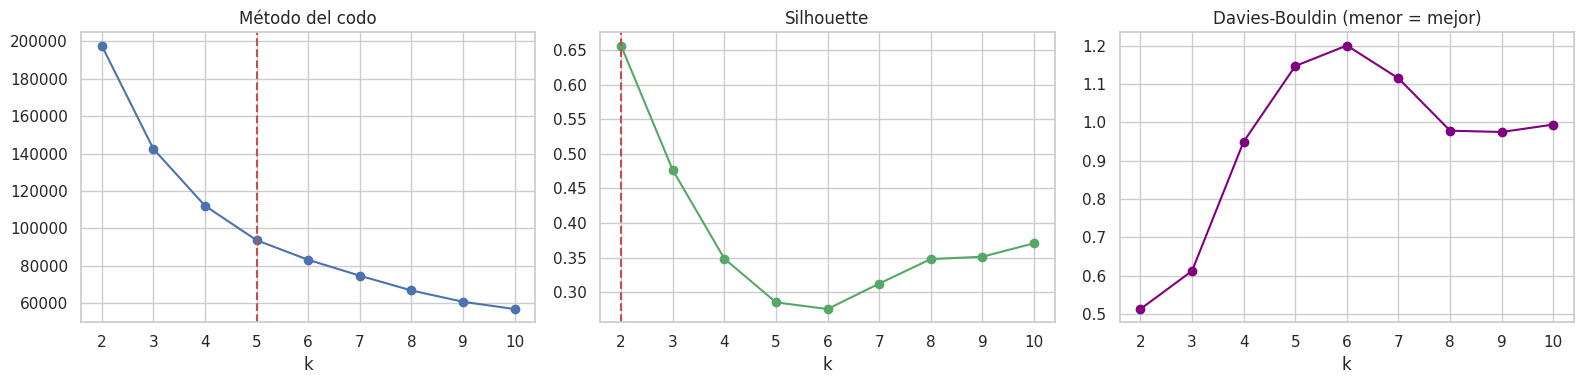

k elegido: 5


In [ ]:
# Celda 11 · K-means: selección de k
rng = np.random.RandomState(SEMILLA)
idx_sil = rng.choice(len(Z), size=min(10000, len(Z)), replace=False)

filas = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    filas.append(dict(k=k, inercia=km_k.inertia_,
                      silhouette=silhouette_score(Z[idx_sil], km_k.labels_[idx_sil]),
                      davies_bouldin=davies_bouldin_score(Z, km_k.labels_),
                      calinski_harabasz=calinski_harabasz_score(Z, km_k.labels_)))
sel = pd.DataFrame(filas).set_index('k')
display(sel)

# codo por distancia máxima a la cuerda que une los extremos de la curva de inercia
ks = sel.index.values.astype(float); ine = sel['inercia'].values
p1, p2 = np.array([ks[0], ine[0]]), np.array([ks[-1], ine[-1]])
dx, dy = p2 - p1
dist = [abs(dx * (p1[1] - i) - (p1[0] - k) * dy) / np.hypot(dx, dy) for k, i in zip(ks, ine)]
k_codo = int(ks[int(np.argmax(dist))])
k_sil = int(sel['silhouette'].idxmax())
print(f'k sugerido por codo: {k_codo} | k con mayor silhouette: {k_sil}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sel['inercia'].plot(marker='o', ax=ax[0]); ax[0].axvline(k_codo, color='r', ls='--'); ax[0].set_title('Método del codo')
sel['silhouette'].plot(marker='o', ax=ax[1], color='g'); ax[1].axvline(k_sil, color='r', ls='--'); ax[1].set_title('Silhouette')
sel['davies_bouldin'].plot(marker='o', ax=ax[2], color='purple'); ax[2].set_title('Davies-Bouldin (menor = mejor)')
plt.tight_layout(); plt.show()

# Regla de decisión: se prioriza silhouette; si codo y silhouette difieren, se usa el de mayor silhouette
# pero se exige k >= 3 para que la segmentación sea útil como descripción de mercado.
K_OPT = k_sil if k_sil >= 3 else max(k_codo, 3)
print('k elegido:', K_OPT)

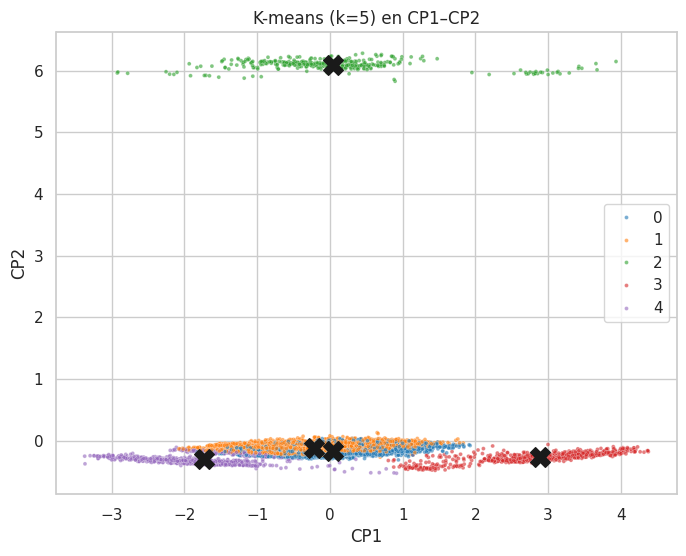

,n,vol_mediano,vol_medio,y_medio,precio_mediano,pct_exentos,% del total
cl_kmeans,,,,,,,
0,18566,50.255,90.038,3.717,99.321,0.000,30.086
1,31127,48.090,80.591,3.661,99.500,0.000,50.441
2,1612,48.035,"6,479.034",4.241,96.000,1.000,2.612
3,5205,"81,105.000","89,513.487",11.230,49.250,0.000,8.435
4,5200,44.013,678.630,3.639,822.000,0.000,8.427


Composición por producto (fila = cluster):


producto,GLPA,GNC,Gas Oil Grado 2,Gas Oil Grado 2B,Gas Oil Grado 3,Kerosene,Nafta (común) hasta 92 Ron,Nafta (premium) de más de 95 Ron,Nafta (súper) entre 92 y 95 Ron
cl_kmeans,,,,,,,,,
0,0.048,0.603,31.455,0.092,23.188,1.196,0.027,20.527,22.864
1,0.000,0.013,29.299,0.016,22.193,1.028,0.042,22.713,24.696
2,0.000,8.809,25.062,0.000,28.164,0.620,0.248,18.424,18.672
3,0.000,95.889,1.306,0.038,0.961,0.019,0.192,0.596,0.999
4,0.019,0.365,20.885,0.000,44.212,0.750,0.135,16.327,17.308


Composición por canal:


canal_de_comercializacion,Agro,Al público,Otros sectores,Reventa a otras estaciones de servicio,Transporte de cargas,Transporte público de pasajeros,Vehículos con placa identificatoria extranjera
cl_kmeans,,,,,,,
0,7.869,79.269,4.158,2.348,5.149,1.207,0.000
1,5.433,86.475,1.934,1.038,4.376,0.684,0.061
2,8.933,83.995,2.233,1.303,2.543,0.993,0.000
3,0.192,98.194,0.403,0.019,0.442,0.749,0.000
4,7.615,82.135,2.788,1.596,4.673,0.654,0.538


Cluster 0: 18,566 filas | producto dominante: Gas Oil Grado 2 (31%) | canal dominante: Al público (79%) | volumen mediano: 50.3
Cluster 1: 31,127 filas | producto dominante: Gas Oil Grado 2 (29%) | canal dominante: Al público (86%) | volumen mediano: 48.1
Cluster 2: 1,612 filas | producto dominante: Gas Oil Grado 3 (28%) | canal dominante: Al público (84%) | volumen mediano: 48.0
Cluster 3: 5,205 filas | producto dominante: GNC (96%) | canal dominante: Al público (98%) | volumen mediano: 81,105.0
Cluster 4: 5,200 filas | producto dominante: Gas Oil Grado 3 (44%) | canal dominante: Al público (82%) | volumen mediano: 44.0


In [ ]:
# Celda 12 · K-means: modelo final, visualización y caracterización
km = KMeans(n_clusters=K_OPT, n_init=20, random_state=SEMILLA).fit(Z)
panel['cl_kmeans'] = km.labels_

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[idx, 0], y=Z[idx, 1], hue=km.labels_[idx], palette='tab10', s=8, alpha=.6)
c2 = km.cluster_centers_[:, :2]
plt.scatter(c2[:, 0], c2[:, 1], marker='X', s=200, c='k')
plt.title(f'K-means (k={K_OPT}) en CP1–CP2'); plt.xlabel('CP1'); plt.ylabel('CP2'); plt.show()

def perfil_clusters(col):
    g = panel.groupby(col)
    t = g.agg(n=('y', 'size'), vol_mediano=('volumen', 'median'), vol_medio=('volumen', 'mean'),
              y_medio=('y', 'mean'), precio_mediano=('precio_con_impuestos', 'median'), pct_exentos=('exentos_i', 'mean'))
    t['% del total'] = t['n'] / t['n'].sum() * 100
    return t

display(perfil_clusters('cl_kmeans'))
print('Composición por producto (fila = cluster):')
display(pd.crosstab(panel['cl_kmeans'], panel['producto'], normalize='index') * 100)
print('Composición por canal:')
display(pd.crosstab(panel['cl_kmeans'], panel['canal_de_comercializacion'], normalize='index') * 100)

# descripción automática: producto y canal dominantes de cada cluster
for c in sorted(panel['cl_kmeans'].unique()):
    d = panel[panel['cl_kmeans'] == c]
    pr = d['producto'].value_counts(normalize=True); ca = d['canal_de_comercializacion'].value_counts(normalize=True)
    print(f'Cluster {c}: {len(d):,} filas | producto dominante: {pr.index[0]} ({pr.iloc[0]:.0%}) | '
          f'canal dominante: {ca.index[0]} ({ca.iloc[0]:.0%}) | volumen mediano: {d.volumen.median():,.1f}')

**Interpretación (ejecución de referencia, semilla 42; los números pueden variar levemente con otras versiones de las librerías).** Con k = 5 K-means separa:
- **Cluster GNC** (~8 % de las filas): casi todo GNC, volumen mediano ≈ 81.000 (frente a ≈ 45–50 de los demás) y precio bajo (≈ 49). Es la estructura dominante y refleja la diferencia de escala del volumen por producto.
- **Cluster de registros exentos** (~3 %): reúne todas las filas con `exentos = 1`.
- **Cluster de precios altos** (~8 %): precios entre ≈ 230 y 1.999 (mediana ≈ 822) frente a ≈ 100 del resto. No está documentado a qué corresponde (otra unidad de precio, otro concepto de reporte, etc.); conviene revisarlo con la fuente.
- **Dos clusters de combustibles líquidos** (~30 % y ~50 %) que se diferencian sobre todo por el **tipo de negocio**: bocas duales (líquidos + GNC) frente a bocas de solo líquidos.

El silhouette más alto aparece en k = 2 (≈ 0,66), que solo separa GNC del resto: una partición demasiado gruesa para describir el mercado. Por eso la regla del notebook exige k ≥ 3 y se toma el codo (k = 5). Es una segmentación válida y descriptiva, pero dos de los grupos (GNC y precios altos) provienen de escalas de `volumen` y de `precio` por producto/registro, no necesariamente de comportamientos comerciales distintos.

### 4.2 DBSCAN
**Idea:** un punto es *núcleo* si tiene al menos `min_samples` vecinos (él incluido) a distancia ≤ `eps`; los clusters son componentes conexas de puntos núcleo y los puntos sin vecindad suficiente son **ruido** (`-1`). No exige fijar el número de clusters y detecta formas arbitrarias y atípicos.

- **`eps`**: radio de vecindad. Muy pequeño → casi todo es ruido; muy grande → todo se fusiona en un solo cluster. Se guía con el gráfico de **k-distancias** (distancia al k-ésimo vecino ordenada): el "codo" sugiere el valor.
- **`min_samples`**: densidad mínima. Regla práctica: ≥ dimensión + 1, comúnmente $2d$ en datos de $d$ dimensiones.

Como DBSCAN usa una sola densidad global, rinde mal si los grupos tienen densidades muy distintas, y esa es una limitación relevante aquí (productos con escalas de volumen muy diferentes).

k-distancias calculadas en 5.2s (min_samples base = 14)
eps sugerido por el codo: 0.230 | percentiles de k-distancia 50/90/95/99: [0.045 0.207 0.337 0.758]


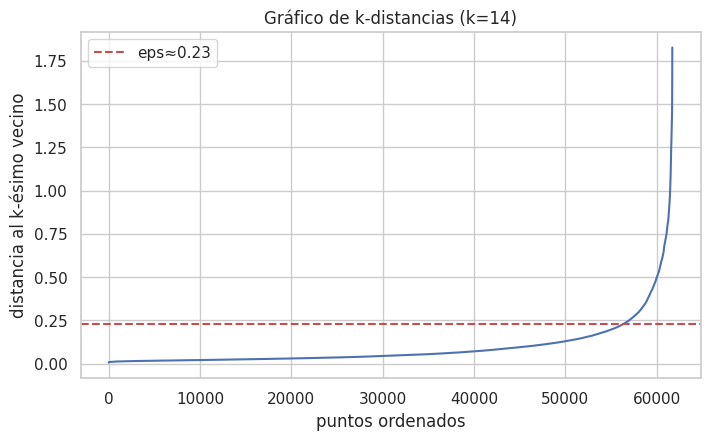

,eps,min_samples,clusters,ruido_pct,mayor_cluster_pct,silhouette
0,0.115,7,104,23.207,6.787,0.309
1,0.115,14,53,34.620,6.653,0.441
2,0.115,28,28,49.327,5.980,0.554
3,0.230,7,94,9.867,11.127,0.238
4,0.230,14,54,16.180,10.927,0.313
5,0.230,28,36,24.487,10.353,0.408
6,0.345,7,76,5.680,11.187,0.265
7,0.345,14,51,10.540,11.147,0.262
8,0.345,28,35,16.660,11.027,0.370


In [ ]:
# Celda 13 · DBSCAN: gráfico de k-distancias y análisis de sensibilidad
d_dim = Z.shape[1]
MS0 = max(2 * d_dim, 10)
t0 = time.time()
nn = NearestNeighbors(n_neighbors=MS0).fit(Z)
kdist = np.sort(nn.kneighbors(Z)[0][:, -1])
print(f'k-distancias calculadas en {time.time()-t0:.1f}s (min_samples base = {MS0})')

# codo de la curva de k-distancias (distancia máxima a la cuerda, ejes normalizados)
xs = np.linspace(0, 1, len(kdist)); ys = (kdist - kdist.min()) / (kdist.max() - kdist.min() + 1e-12)
EPS0 = float(kdist[int(np.argmax(np.abs(ys - xs)))])
print(f'eps sugerido por el codo: {EPS0:.3f} | percentiles de k-distancia 50/90/95/99: '
      f'{np.percentile(kdist,[50,90,95,99]).round(3)}')

plt.figure(figsize=(8, 4.5)); plt.plot(kdist); plt.axhline(EPS0, color='r', ls='--', label=f'eps≈{EPS0:.2f}')
plt.title(f'Gráfico de k-distancias (k={MS0})'); plt.xlabel('puntos ordenados'); plt.ylabel('distancia al k-ésimo vecino'); plt.legend(); plt.show()

# Sensibilidad en una muestra (DBSCAN es costoso en memoria cuando hay muchos puntos casi idénticos)
N_MUESTRA = 15000
im = np.random.RandomState(SEMILLA).choice(len(Z), N_MUESTRA, replace=False)
Zm = Z[im]
res = []
for f_eps in [0.5, 1.0, 1.5]:
    for f_ms in [0.5, 1, 2]:
        eps, ms = EPS0 * f_eps, int(MS0 * f_ms)
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zm)
        mask = lab != -1; ncl = len(set(lab[mask]))
        sil = np.nan
        if ncl >= 2:
            ii = np.random.RandomState(SEMILLA).choice(np.where(mask)[0], min(5000, mask.sum()), replace=False)
            sil = silhouette_score(Zm[ii], lab[ii])
        res.append(dict(eps=eps, min_samples=ms, clusters=ncl, ruido_pct=(~mask).mean() * 100,
                        mayor_cluster_pct=(np.bincount(lab[mask]).max() / len(lab) * 100) if ncl else 0, silhouette=sil))
sens = pd.DataFrame(res)
display(sens)

Configuración elegida: eps=0.345, min_samples=7
Clusters: 110 | ruido: 1,162 (1.9%)


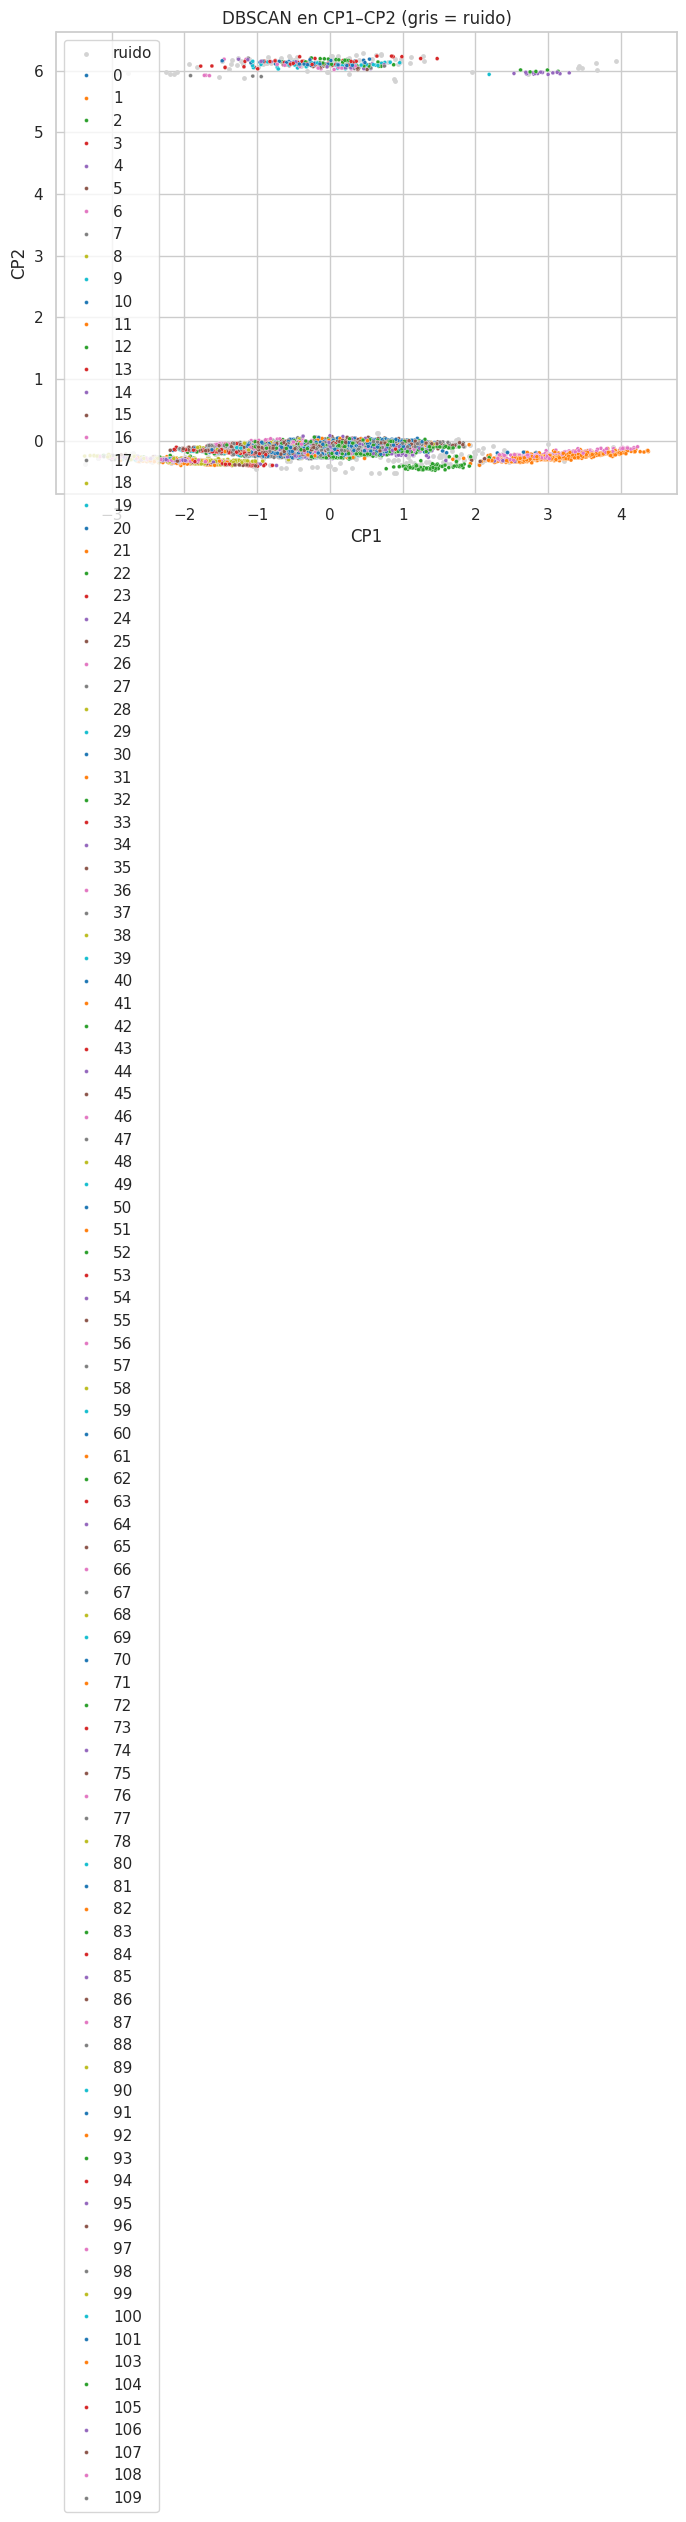

,n,vol_mediano,vol_medio,y_medio,precio_mediano,pct_exentos,% del total
cl_dbscan,,,,,,,
7,7084,103.000,125.086,4.396,98.500,0.000,11.480
0,6924,51.666,91.350,3.907,92.775,0.000,11.220
5,6637,39.063,59.613,3.493,113.500,0.000,10.755
2,5916,44.134,60.477,3.649,107.800,0.000,9.587
22,3419,124.940,135.774,4.644,98.000,0.000,5.540
11,3363,"85,307.000","92,196.216",11.299,46.990,0.000,5.450
14,3249,45.077,82.536,3.769,93.000,0.000,5.265
20,3229,46.352,58.873,3.617,114.000,0.000,5.233
16,2707,41.390,54.662,3.570,108.400,0.000,4.387


Composición por producto de los 15 grupos más grandes y del ruido (-1):


producto,GLPA,GNC,Gas Oil Grado 2,Gas Oil Grado 2B,Gas Oil Grado 3,Kerosene,Nafta (común) hasta 92 Ron,Nafta (premium) de más de 95 Ron,Nafta (súper) entre 92 y 95 Ron
cl_dbscan,,,,,,,,,
-1,0.861,11.532,20.568,1.807,19.363,9.552,1.807,16.007,18.503
0,0.000,0.000,100.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.000,0.000,0.000,0.000,100.000,0.000,0.000,0.000,0.000
3,0.000,0.000,0.000,0.000,100.000,0.000,0.000,0.000,0.000
5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.000,0.000
7,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.000
11,0.000,99.762,0.000,0.000,0.000,0.030,0.208,0.000,0.000
14,0.000,0.000,100.000,0.000,0.000,0.000,0.000,0.000,0.000
16,0.000,0.000,0.000,0.000,100.000,0.000,0.000,0.000,0.000


Pureza de producto: el 97% de los clusters DBSCAN tiene >95% de un solo producto
El ruido son observaciones raras (combinaciones poco frecuentes o volúmenes extremos):


,periodo,producto,canal_de_comercializacion,volumen,precio_con_impuestos
3678,2022-01-01,GNC,Al público,"1,110,980.000",50.480
22726,2023-01-01,GNC,Al público,"891,980.000",77.990
40709,2023-01-01,Gas Oil Grado 2,Agro,"678,900.000",199.900
60734,2022-01-01,Gas Oil Grado 2,Transporte de cargas,"594,500.000",92.470
60732,2022-01-01,Gas Oil Grado 2,Otros sectores,"465,350.000",93.180
60735,2022-02-01,Gas Oil Grado 2,Transporte de cargas,"386,766.000",99.320
60738,2022-02-01,Gas Oil Grado 3,Otros sectores,"367,500.000",117.670
60733,2022-02-01,Gas Oil Grado 2,Otros sectores,"340,300.000",101.320


In [ ]:
# Celda 14 · DBSCAN: configuración elegida, ajuste final, ruido y caracterización
# Regla: entre configuraciones con >=2 clusters y ruido <= 15 %, la de mayor silhouette;
# si ninguna cumple, la más cercana al eps sugerido por el codo.
cand = sens[(sens.clusters >= 2) & (sens.ruido_pct <= 15)].dropna(subset=['silhouette'])
if len(cand):
    mejor = cand.sort_values('silhouette', ascending=False).iloc[0]
else:
    mejor = sens.iloc[(sens.eps - EPS0).abs().argsort().iloc[0]]
EPS, MS = float(mejor['eps']), int(mejor['min_samples'])
print(f'Configuración elegida: eps={EPS:.3f}, min_samples={MS}')

db = DBSCAN(eps=EPS, min_samples=MS).fit(Z)
panel['cl_dbscan'] = db.labels_
n_cl_db = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f'Clusters: {n_cl_db} | ruido: {(db.labels_==-1).sum():,} ({(db.labels_==-1).mean():.1%})')

plt.figure(figsize=(8, 6))
lab_i = db.labels_[idx]
plt.scatter(Z[idx][lab_i == -1, 0], Z[idx][lab_i == -1, 1], s=6, c='lightgray', label='ruido')
sns.scatterplot(x=Z[idx][lab_i != -1, 0], y=Z[idx][lab_i != -1, 1], hue=lab_i[lab_i != -1], palette='tab10', s=8)
plt.title('DBSCAN en CP1–CP2 (gris = ruido)'); plt.xlabel('CP1'); plt.ylabel('CP2'); plt.show()

display(perfil_clusters('cl_dbscan').sort_values('n', ascending=False).head(15))
print('Composición por producto de los 15 grupos más grandes y del ruido (-1):')
top = panel['cl_dbscan'].value_counts().head(15).index.union([-1])
display(pd.crosstab(panel['cl_dbscan'], panel['producto'], normalize='index').loc[top] * 100)
pureza = (pd.crosstab(panel['cl_dbscan'], panel['producto'], normalize='index').drop(index=-1, errors='ignore').max(axis=1))
print(f'Pureza de producto: el {(pureza > 0.95).mean():.0%} de los clusters DBSCAN tiene >95% de un solo producto')
print('El ruido son observaciones raras (combinaciones poco frecuentes o volúmenes extremos):')
display(panel[panel.cl_dbscan == -1].nlargest(8, 'volumen')[['periodo', 'producto', 'canal_de_comercializacion', 'volumen', 'precio_con_impuestos']])

### 4.3 Comparación de algoritmos
Para que la comparación sea justa, las métricas internas (silhouette, Davies-Bouldin, Calinski-Harabasz) se calculan **solo sobre los puntos que DBSCAN no marcó como ruido**, y se calculan para K-means sobre ese mismo subconjunto. Estas métricas favorecen clusters compactos y convexos, por lo que **penalizan a DBSCAN por construcción**; se interpretan junto con la geometría de los datos y no como veredicto único.

In [ ]:
# Celda 15 · Comparación K-means vs DBSCAN
mask = panel['cl_dbscan'].values != -1
idx_ok = np.where(mask)[0]
ii = np.random.RandomState(SEMILLA).choice(idx_ok, min(10000, len(idx_ok)), replace=False)

def metricas_cluster(Zs, lab, ii):
    ok = len(set(lab)) >= 2
    return dict(silhouette=silhouette_score(Zs[ii], lab[ii]) if ok else np.nan,
                davies_bouldin=davies_bouldin_score(Zs, lab) if ok else np.nan,
                calinski_harabasz=calinski_harabasz_score(Zs, lab) if ok else np.nan)

comp = pd.DataFrame({
    'K-means': dict(clusters=K_OPT, obs_agrupadas=len(Z), ruido=0, **metricas_cluster(Z, panel.cl_kmeans.values, idx_sil)),
    'K-means (sin puntos-ruido de DBSCAN)': dict(clusters=len(set(panel.cl_kmeans.values[mask])), obs_agrupadas=int(mask.sum()), ruido=0,
                                                 **metricas_cluster(Z[mask], panel.cl_kmeans.values[mask], np.searchsorted(idx_ok, np.sort(ii)))),
    'DBSCAN': dict(clusters=n_cl_db, obs_agrupadas=int(mask.sum()), ruido=int((~mask).sum()),
                   **metricas_cluster(Z[mask], panel.cl_dbscan.values[mask], np.searchsorted(idx_ok, np.sort(ii)))),
}).T
display(comp)
if n_cl_db >= 1:
    print('Adjusted Rand Index entre ambas particiones (solo no-ruido):',
          round(adjusted_rand_score(panel.cl_kmeans.values[mask], panel.cl_dbscan.values[mask]), 3))
print('\nSensibilidad: K-means depende de k (y de la inicialización); DBSCAN depende de eps y min_samples (ver tabla de la celda 13).')

,clusters,obs_agrupadas,ruido,silhouette,davies_bouldin,calinski_harabasz
K-means,5.000,"61,710.000",0.000,0.286,1.147,"27,349.728"
K-means (sin puntos-ruido de DBSCAN),5.000,"60,548.000",0.000,0.289,1.133,"25,342.448"
DBSCAN,110.000,"60,548.000","1,162.000",0.237,1.015,"3,941.606"


Adjusted Rand Index entre ambas particiones (solo no-ruido): 0.216

Sensibilidad: K-means depende de k (y de la inicialización); DBSCAN depende de eps y min_samples (ver tabla de la celda 13).


**Ventajas y limitaciones**

| | K-means | DBSCAN |
|---|---|---|
| Fortalezas | Rápido, asigna todas las observaciones, centroides interpretables, métricas internas bien definidas | No requiere fijar *k*, encuentra formas arbitrarias, aísla atípicos como ruido |
| Debilidades | Asume grupos esféricos y de tamaño parecido; los atípicos arrastran los centroides; hay que elegir *k* | Una sola densidad global; muy sensible a `eps`; en datos mixtos con dummies, muchos puntos casi idénticos generan un cluster gigante |
| Geometría de estos datos | Las dummies de producto/canal/tipo de negocio crean grupos compactos y bien separados, y `y`/`log_precio` forman nubes continuas dentro de cada uno → K-means los captura con pocos grupos | Con una densidad global, DBSCAN rodea cada combinación densa y la separa: produce **decenas de clusters pequeños casi puros en un producto** en lugar de segmentos de mercado |

**Decisión.** Para **segmentar el mercado** es más apropiado **K-means**: los datos son mixtos (categorías + magnitudes), la estructura dominante son pocos grupos compactos asociados al producto, al tipo de negocio y al nivel de precio, y se necesita asignar todas las observaciones. En la ejecución de referencia DBSCAN (eps ≈ 0,35, `min_samples` = 7) devolvió **110 clusters** casi puros en un producto (ARI ≈ 0,22 frente a K-means), con ≈ 1,9 % de ruido; su silhouette es menor y su índice de Calinski-Harabasz mucho menor que el de K-means, aunque su Davies-Bouldin es algo mejor. Esa fragmentación es demasiado fina para interpretar. Donde **sí** aporta DBSCAN es como **detector de observaciones raras**: su ruido contiene los volúmenes extremos (GNC de más de 800.000, gasoil de hasta ≈ 680.000 en canales Agro, Transporte de cargas y Otros sectores), candidatos a revisar por posibles errores de carga o de unidad. Se recomienda usar K-means para segmentar y DBSCAN para auditar atípicos.

## 5. Representaciones vectoriales, similitud y base de datos vectorial

**¿Hay variables textuales?** Sí, pero son **texto corto y categórico** (operador, bandera, tipo de negocio, localidad, provincia, producto, canal), no texto libre. Por eso un embedding de lenguaje aporta una similitud *semántica y ortográfica* entre nombres (p. ej. "Estación de Servicio" ≈ "Est. de Servicios", marcas y localidades parecidas), pero **no captura el comportamiento de ventas**: dos estaciones con texto parecido pueden vender volúmenes muy distintos. Por eso las variables numéricas (`y_medio`, `n_obs`) se guardan como **metadatos** y no dentro del embedding.

**Construcción de la representación.**
- *Preferida:* `sentence-transformers` (`paraphrase-multilingual-MiniLM-L12-v2`), un Transformer que convierte cada texto en un vector denso de 384 dimensiones.
- *Alternativa sin descargas:* TF-IDF de n-gramas de caracteres + SVD (LSA), un embedding clásico y determinista. La celda cae en esta opción si el modelo no puede descargarse.

Los vectores se normalizan (norma 1). **Similitud coseno:** $\cos(a,b)=\frac{a\cdot b}{\|a\|\|b\|}$; **distancia coseno** $=1-\cos(a,b)$. Con vectores unitarios el coseno es el producto punto.

In [ ]:
# Celda 16 · Documentos de texto (una fila por combinación única) y embeddings
panel['texto'] = (panel['operador'].str.title() + ' | bandera ' + panel['bandera'].str.title() + ' | ' +
                  panel['tipo_negocio'] + ' | ' + panel['localidad'].str.title() + ', ' + panel['provincia'].str.title() +
                  ' | ' + panel['producto'] + ' | canal ' + panel['canal_de_comercializacion'])

docs = (panel.groupby('texto')
             .agg(n_obs=('y', 'size'), y_medio=('y', 'mean'), provincia=('provincia', 'first'),
                  producto=('producto', 'first'), bandera=('bandera', 'first'), canal=('canal_de_comercializacion', 'first'))
             .reset_index())
docs['id'] = ['doc_' + str(i) for i in range(len(docs))]
print('Documentos únicos:', len(docs))
print('Ejemplo:', docs['texto'].iloc[0])

def construir_embedder(textos):
    if USAR_SENTENCE_TRANSFORMERS:
        try:
            from sentence_transformers import SentenceTransformer
            modelo = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
            fn = lambda t: modelo.encode(list(t), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
            return 'sentence-transformers (MiniLM multilingüe)', fn
        except Exception as e:
            print('sentence-transformers no disponible, se usa TF-IDF + SVD. Motivo:', repr(e)[:120])
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import Normalizer
    tfidf = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
    svd = TruncatedSVD(n_components=128, random_state=SEMILLA)
    norm = Normalizer()
    svd.fit(tfidf.fit_transform(textos))
    fn = lambda t: norm.transform(svd.transform(tfidf.transform(list(t))))
    return 'TF-IDF (n-gramas de caracteres) + SVD', fn

nombre_emb, embed = construir_embedder(docs['texto'].tolist())
t0 = time.time()
E = np.asarray(embed(docs['texto'].tolist()), dtype='float32')
print(f'Embeddings: {nombre_emb} | forma {E.shape} | {time.time()-t0:.1f}s | norma media {np.linalg.norm(E, axis=1).mean():.3f}')

Documentos únicos: 24011
Ejemplo: 10 De Setiembre S.A. | bandera Blanca | Bocas de expendio (venta por menor) Duales (líquidos + GNC) | Lomas Del Mirador, Buenos Aires | GNC | canal Al público


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings: sentence-transformers (MiniLM multilingüe) | forma (24011, 384) | 1562.4s | norma media 1.000


In [ ]:
# Celda 17 · Similitud coseno y observaciones similares
def similares(i, k=6):
    sim = E @ E[i]                                  # vectores unitarios: producto punto = coseno
    orden = np.argsort(-sim)[1:k + 1]
    out = docs.iloc[orden][['texto', 'producto', 'provincia', 'y_medio']].copy()
    out['similitud_coseno'] = sim[orden]; out['distancia_coseno'] = 1 - sim[orden]
    return out

cand = docs[(docs.bandera == 'YPF') & (docs.producto == 'GNC') & (docs.provincia == 'BUENOS AIRES')]
ref = int(cand.index[0]) if len(cand) else 0
print('Referencia:', docs.loc[ref, 'texto'])
display(similares(ref))

# verificación contra la implementación de scikit-learn
sk = cosine_similarity(E[ref:ref + 1], E)[0]
assert np.allclose(sk, E @ E[ref], atol=1e-4), 'el producto punto no coincide con cosine_similarity'
print('OK: producto punto == cosine_similarity para vectores normalizados')

# Clustering sobre los embeddings (K-means esférico por vectores normalizados)
ks_emb, sil_emb = [4, 6, 8, 10, 12], []
for k in ks_emb:
    l = KMeans(n_clusters=k, n_init=5, random_state=SEMILLA).fit_predict(E)
    sil_emb.append(silhouette_score(E, l, metric='cosine', sample_size=min(8000, len(E)), random_state=SEMILLA))
print(dict(zip(ks_emb, np.round(sil_emb, 3))))
k_emb = ks_emb[int(np.argmax(sil_emb))]
docs['cl_emb'] = KMeans(n_clusters=k_emb, n_init=10, random_state=SEMILLA).fit_predict(E)
print('k elegido para embeddings:', k_emb)
display(pd.crosstab(docs['cl_emb'], docs['producto'], normalize='index').round(2) * 100)
display(docs.groupby('cl_emb').agg(docs=('texto', 'size'), prov_principal=('provincia', lambda s: s.value_counts().index[0]),
                                   bandera_principal=('bandera', lambda s: s.value_counts().index[0]), y_medio=('y_medio', 'mean')))

Referencia: Abanillas S.A. | bandera Ypf | Bocas de expendio (venta por menor) Duales (líquidos + GNC) | Lomas De Zamora, Buenos Aires | GNC | canal Al público


,texto,producto,provincia,y_medio,similitud_coseno,distancia_coseno
240,Abanillas S.A. | bandera Ypf | Bocas de expend...,Nafta (súper) entre 92 y 95 Ron,BUENOS AIRES,5.085,0.975,0.025
7874,Da Costa E Hijos S.A. | bandera Ypf | Bocas de...,GNC,BUENOS AIRES,11.880,0.969,0.031
1023,Aguero Norte S.R.L | bandera Ypf | Bocas de ex...,GNC,BUENOS AIRES,10.814,0.968,0.032
22425,Socoroma S.A. | bandera Ypf | Bocas de expendi...,GNC,BUENOS AIRES,11.528,0.967,0.033
1411,Alli Vamos S.A. | bandera Ypf | Bocas de expen...,GNC,BUENOS AIRES,12.076,0.966,0.034
18774,Pesues S.A. | bandera Ypf | Bocas de expendio ...,GNC,BUENOS AIRES,11.432,0.965,0.035


OK: producto punto == cosine_similarity para vectores normalizados
{4: np.float32(0.163), 6: np.float32(0.16), 8: np.float32(0.166), 10: np.float32(0.155), 12: np.float32(0.123)}
k elegido para embeddings: 8


producto,GLPA,GNC,Gas Oil Grado 2,Gas Oil Grado 2B,Gas Oil Grado 3,Kerosene,Nafta (común) hasta 92 Ron,Nafta (premium) de más de 95 Ron,Nafta (súper) entre 92 y 95 Ron
cl_emb,,,,,,,,,
0,0.000,55.000,3.000,0.000,1.000,2.000,0.000,16.000,23.000
1,0.000,1.000,39.000,0.000,34.000,1.000,0.000,11.000,14.000
2,0.000,0.000,55.000,1.000,36.000,1.000,0.000,3.000,5.000
3,0.000,0.000,0.000,0.000,0.000,2.000,0.000,48.000,49.000
4,0.000,31.000,0.000,0.000,0.000,2.000,0.000,32.000,36.000
5,0.000,8.000,42.000,0.000,38.000,0.000,0.000,6.000,6.000
6,0.000,15.000,20.000,0.000,19.000,0.000,0.000,23.000,22.000
7,0.000,0.000,49.000,0.000,44.000,0.000,0.000,3.000,3.000


,docs,prov_principal,bandera_principal,y_medio
cl_emb,,,,
0,1021,BUENOS AIRES,BLANCA,7.435
1,4353,BUENOS AIRES,YPF,3.566
2,1254,BUENOS AIRES,YPF,3.643
3,4801,BUENOS AIRES,YPF,3.590
4,3542,BUENOS AIRES,YPF,6.166
5,4095,BUENOS AIRES,YPF,4.096
6,718,CAPITAL FEDERAL,YPF,5.085
7,4227,SANTA FE,YPF,3.520


### Base de datos vectorial con ChromaDB
- **Almacenamiento:** cada documento se guarda con su *embedding*, el texto original y **metadatos** (provincia, producto, bandera, canal, `n_obs`, `y_medio`).
- **Indexación:** Chroma construye un índice **HNSW** (*Hierarchical Navigable Small World*): un grafo por capas que permite buscar vecinos aproximados en tiempo ≈ logarítmico, en lugar de comparar contra todos los vectores (búsqueda exacta, $O(n)$).
- **Recuperación por similitud:** `query` devuelve los *n* vectores más cercanos según la métrica de la colección (aquí coseno; Chroma devuelve la **distancia** $=1-\cos$).
- **Consultas vectoriales:** por texto (se embebe la consulta con el mismo modelo), por vector o por documento existente, combinables con **filtros de metadatos** (`where`).
- **Aplicaciones en este caso:** buscar establecimientos comparables, imputar o estimar el nivel de ventas de una estación nueva con los vecinos más parecidos, detectar duplicados o variantes de nombre de un mismo operador, y recuperar contexto para un asistente generativo (RAG).

In [ ]:
# Celda 18 · ChromaDB: crear colección, indexar y consultar
import chromadb

cliente = chromadb.Client()                         # base en memoria (se pierde al reiniciar el entorno)
try:
    cliente.delete_collection('eess')
except Exception:
    pass
ESPACIO = 'cosine'
try:                                                # versiones recientes de Chroma
    col = cliente.create_collection('eess', configuration={'hnsw': {'space': 'cosine'}})
except Exception:
    try:                                            # versiones anteriores
        col = cliente.create_collection('eess', metadata={'hnsw:space': 'cosine'})
    except Exception:                               # último recurso: L2 (con vectores unitarios el orden es el mismo)
        col = cliente.create_collection('eess'); ESPACIO = 'l2'
        print('Aviso: se usa distancia L2; con vectores unitarios, distancia coseno = L2² / 2')

LOTE = 2000
for i in range(0, len(docs), LOTE):
    b = docs.iloc[i:i + LOTE]
    col.add(ids=b['id'].tolist(),
            embeddings=E[i:i + LOTE].tolist(),
            documents=b['texto'].tolist(),
            metadatas=[{'provincia': r.provincia, 'producto': r.producto, 'bandera': r.bandera, 'canal': r.canal,
                        'n_obs': int(r.n_obs), 'y_medio': float(r.y_medio)} for r in b.itertuples()])
print('Documentos indexados:', col.count())

def mostrar(res):
    return pd.DataFrame({'texto': res['documents'][0], 'distancia_coseno': [d if ESPACIO == 'cosine' else d / 2 for d in res['distances'][0]],
                         'producto': [m['producto'] for m in res['metadatas'][0]],
                         'provincia': [m['provincia'] for m in res['metadatas'][0]],
                         'y_medio': [m['y_medio'] for m in res['metadatas'][0]]})

consulta = 'YPF estación de servicio GNC La Plata Buenos Aires'
q = np.asarray(embed([consulta]), dtype='float32')
inc = ['documents', 'distances', 'metadatas']

print('1) Consulta por texto:', consulta)
display(mostrar(col.query(query_embeddings=q.tolist(), n_results=5, include=inc)))

print('2) Misma consulta con filtro de metadatos (producto = GNC y provincia = BUENOS AIRES):')
display(mostrar(col.query(query_embeddings=q.tolist(), n_results=5, include=inc,
                          where={'$and': [{'producto': 'GNC'}, {'provincia': 'BUENOS AIRES'}]})))

print('3) Vecinos del documento de referencia:')
display(mostrar(col.query(query_embeddings=E[ref:ref + 1].tolist(), n_results=6, include=inc)))

# contraste con búsqueda exacta (fuerza bruta)
exacto = set(np.argsort(-(E @ q[0]))[:5]); aprox = set(int(i.split('_')[1]) for i in col.query(query_embeddings=q.tolist(), n_results=5)['ids'][0])
print(f'Coincidencia HNSW vs búsqueda exacta en el top-5: {len(exacto & aprox)}/5')

Documentos indexados: 24011
1) Consulta por texto: YPF estación de servicio GNC La Plata Buenos Aires


,texto,distancia_coseno,producto,provincia,y_medio
0,Centro Pampeana Comercial Srl | bandera Ypf | ...,0.196,GNC,BUENOS AIRES,11.388
1,Elisei Hnos. | bandera Ypf | Estación de servi...,0.213,GNC,BUENOS AIRES,12.073
2,Complejo Tala Del Monte S.A. | bandera Ypf | E...,0.217,GNC,BUENOS AIRES,11.236
3,Centro Pampeana Comercial Srl | bandera Ypf | ...,0.232,Nafta (súper) entre 92 y 95 Ron,BUENOS AIRES,5.360
4,Centro Pampeana Comercial Srl | bandera Ypf | ...,0.235,Nafta (premium) de más de 95 Ron,BUENOS AIRES,5.050


2) Misma consulta con filtro de metadatos (producto = GNC y provincia = BUENOS AIRES):


,texto,distancia_coseno,producto,provincia,y_medio
0,Centro Pampeana Comercial Srl | bandera Ypf | ...,0.196,GNC,BUENOS AIRES,11.388
1,Elisei Hnos. | bandera Ypf | Estación de servi...,0.213,GNC,BUENOS AIRES,12.073
2,Complejo Tala Del Monte S.A. | bandera Ypf | E...,0.217,GNC,BUENOS AIRES,11.236
3,Plataforma Urbana Srl | bandera Ypf | Bocas de...,0.237,GNC,BUENOS AIRES,11.809
4,Diaz C. Y Rios J. | bandera Ypf | Estación de ...,0.265,GNC,BUENOS AIRES,11.082


3) Vecinos del documento de referencia:


,texto,distancia_coseno,producto,provincia,y_medio
0,Abanillas S.A. | bandera Ypf | Bocas de expend...,0.000,GNC,BUENOS AIRES,11.299
1,Abanillas S.A. | bandera Ypf | Bocas de expend...,0.025,Nafta (súper) entre 92 y 95 Ron,BUENOS AIRES,5.085
2,Da Costa E Hijos S.A. | bandera Ypf | Bocas de...,0.031,GNC,BUENOS AIRES,11.880
3,Aguero Norte S.R.L | bandera Ypf | Bocas de ex...,0.032,GNC,BUENOS AIRES,10.814
4,Socoroma S.A. | bandera Ypf | Bocas de expendi...,0.033,GNC,BUENOS AIRES,11.528
5,Alli Vamos S.A. | bandera Ypf | Bocas de expen...,0.034,GNC,BUENOS AIRES,12.076


Coincidencia HNSW vs búsqueda exacta en el top-5: 5/5


## 7. Soporte teórico de los errores

**Métricas de regresión** (con $n$ observaciones, $e_i=y_i-\hat y_i$):

| Métrica | Fórmula | Lectura |
|---|---|---|
| MAE | $\frac1n\sum\lvert e_i\rvert$ | Error medio en las unidades del objetivo; robusto a atípicos. |
| MSE | $\frac1n\sum e_i^2$ | Penaliza cuadráticamente los errores grandes; es la pérdida que se optimiza. |
| RMSE | $\sqrt{\text{MSE}}$ | Misma unidad que el objetivo; más sensible a atípicos que el MAE. RMSE ≫ MAE indica errores grandes aislados. |
| R² | $1-\frac{\sum e_i^2}{\sum (y_i-\bar y)^2}$ | Proporción de varianza explicada **respecto de predecir siempre la media**. Puede ser negativo en datos nuevos. |

**Error en escala logarítmica.** Un error $e$ en $\log(1+y)$ equivale a un error **relativo** de $\approx e^{e}-1$. Por eso el RMSE en escala log trata igual a un error del 50 % en una estación chica o grande, mientras que el RMSE original lo domina el volumen absoluto. La transformación inversa $\exp(\hat y)-1$ de un promedio en log estima la **mediana** condicional, no la media (se subestima la media si la distribución es asimétrica).

**Descomposición del error:** $\mathbb{E}[(y-\hat f)^2]=\text{sesgo}^2+\text{varianza}+\sigma^2_{\text{irreducible}}$.
- **Subajuste (alto sesgo):** error alto en train **y** en validación; el modelo es demasiado simple (p. ej. el perceptrón frente al MLP). Acción: más capacidad o mejores variables.
- **Sobreajuste (alta varianza):** error muy bajo en train y notablemente mayor en validación; la curva de validación sube mientras la de entrenamiento baja. Acciones: *early stopping*, Dropout, L2, menos parámetros, más datos.
- **Cambio de distribución (*drift*):** si el error de **prueba** supera al de validación sin señales de sobreajuste, el futuro difiere del pasado (precios nominales que cambian por inflación, otra composición de estaciones). Es el riesgo central de pronosticar con datos de pocos períodos.

**Fuga de información (*data leakage*).** Es un error de *diseño*, no de cálculo: métricas anormalmente buenas en validación y malas en producción. Fuentes típicas: ajustar el escalador/imputador con todos los datos, partir al azar series temporales, usar variables del mismo período que no se conocen al predecir, o usar clusters calculados con el objetivo.

**Línea base.** Un modelo solo aporta valor si supera a la **persistencia** ("el volumen será el del último período observado"), que es muy competitiva en series con memoria. Mejorar sobre la mediana por producto es una condición necesaria pero débil.

**Incertidumbre.** Con 8 períodos y cobertura desigual, las diferencias pequeñas entre modelos pueden no ser significativas; conviene repetir con varias semillas y, si hubiera más períodos, usar validación cruzada temporal (*rolling origin*).

| Síntoma | Diagnóstico probable | Qué hacer |
|---|---|---|
| Train ≪ val ≈ test | Sobreajuste | Regularizar, simplificar, parar antes |
| Train ≈ val ≈ test, todos altos | Subajuste o falta de señal | Más variables, más capacidad |
| val bajo, test alto | Drift temporal | Revisar variables nominales (precios), reentrenar con datos recientes |
| Resultado "demasiado bueno" | Posible fuga | Auditar variables y orden del *fit* del preprocesamiento |
| R² original negativo, R² log positivo | Unos pocos valores gigantes dominan | Reportar ambas escalas; revisar atípicos y unidades |

In [ ]:
# Celda 27 · Resumen automático de resultados
t_test = tabla[tabla.split == 'test'].set_index('modelo')
pers = t_test.loc['Baseline 2: persistencia (último valor)', 'RMSE_log']
print('RMSE_log en TEST (menor es mejor):')
for n, r in t_test['RMSE_log'].sort_values().items():
    print(f'  {n:<48s} {r:6.3f}   ({(1 - r / pers) * 100:+6.1f}% vs persistencia)')
print(f'\nModelo elegido por validación: {mejor}')
print(f"RMSE_log test = {t_test.loc[mejor,'RMSE_log']:.3f} | MAE_log = {t_test.loc[mejor,'MAE_log']:.3f} | R2_log = {t_test.loc[mejor,'R2_log']:.3f}")

RMSE_log en TEST (menor es mejor):
  Referencia: Gradient Boosting                     1.058   (  +8.5% vs persistencia)
  Baseline 2: persistencia (último valor)           1.157   (  +0.0% vs persistencia)
  MLP (128-64-32, dropout + L2)                     1.158   (  -0.1% vs persistencia)
  MLP grande sin regularización (sobreajuste)       1.220   (  -5.4% vs persistencia)
  Perceptrón simple (sigmoide)                      1.304   ( -12.7% vs persistencia)
  Baseline 1: mediana por producto                  1.657   ( -43.1% vs persistencia)

Modelo elegido por validación: MLP (128-64-32, dropout + L2)
RMSE_log test = 1.158 | MAE_log = 0.734 | R2_log = 0.790


## 8. Conclusiones
**Qué se puede afirmar con rigor**
- El conjunto tiene **solo 8 períodos** y cobertura muy desigual por establecimiento: el "futuro" evaluado es **2024-01** a partir de datos previos, no un pronóstico mensual continuo.
- La estructura de los datos está dominada por **producto** (GNC con magnitudes de volumen mucho mayores), por el **tipo de negocio** y por registros de **precio atípicamente alto**; SVD resume el 91 % de la varianza en 7 componentes.
- **K-means** (k = 5) segmenta mejor el mercado; **DBSCAN** fragmenta en decenas de grupos puros y es más útil para **detectar observaciones extremas**.
- Comparar los modelos neuronales **siempre contra la persistencia**: es la referencia que importa para estimar volumen futuro.

**Limitaciones**
- La **unidad de `volumen` y de los precios altos no está documentada**; no se asumió ninguna.
- Sin estacionalidad estimable (casi todo es enero) y con inflación en los precios nominales (riesgo de *drift*).
- Las filas **sin historial** (primer registro de una clave) solo pueden predecirse con atributos estáticos; su error es mayor.
- Muestra posiblemente no representativa de todo el mercado.
